# Laboratorio 3 - La tarea de clasificación

Integrantes:
- Juan Felipe Saenz - 202311148
- Tomas Aguilera - 202321962

En este laboratorio trabajamos el caso de Ruta Alpes, una app de conducción que le muestra cupones a los conductores mientras van manejando. La idea es construir modelos que digan, para un escenario de conducción y un conductor, si es probable que acepte el cupón o no. Nos piden trabajar solo con dos tipos de cupón, "Cafetería" y "Restaurante(<20)", y hacer un modelo separado para cada uno, comparando regresión logística, árboles de decisión y Random Forest. Además hay que revisar si balancear las clases ayuda en el caso de Restaurante(<20), mirar qué variables pesan más y pensar en los riesgos de sesgo de usar datos demográficos para personalizar ofertas.

El notebook está organizado siguiendo las actividades del enunciado (1 a 10) y al final están las respuestas de la sección de análisis de resultados y el registro del uso de IA generativa.

## Importamos librerías

In [1]:
import os
# En Windows joblib intenta contar los nucleos fisicos con un comando que ya no existe
# y llena la salida con un traceback, con esto se evita
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(max(1, os.cpu_count() - 1)))

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score, make_scorer, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

RANDOM_STATE = 42
TIPOS = ["Cafetería", "Restaurante(<20)"]

## Cargamos los datos

Tenemos tres archivos en la carpeta `Data`: los datos etiquetados (`Lab3_Datos.xlsx`), los datos de prueba sin etiqueta sobre los que hay que entregar predicciones (`Lab3_datos_Prueba.xlsx`) y el diccionario de datos.

In [2]:
datos = pd.read_excel("Data/Lab3_Datos.xlsx")
prueba = pd.read_excel("Data/Lab3_datos_Prueba.xlsx")
diccionario = pd.read_excel("Data/Lab3_diccionario_Datos.xlsx")

print("Datos etiquetados:", datos.shape)
print("Datos de prueba (sin etiqueta):", prueba.shape)

Datos etiquetados: (12664, 26)
Datos de prueba (sin etiqueta): (20, 25)


In [3]:
diccionario

,Variable,Tipo,Descripción
0,destino,Categórica nominal,Destino del trayecto en el momento en que se o...
1,acompanante,Categórica nominal,Tipo de acompañante(s) en el vehículo al momen...
2,clima,Categórica nominal,Condición climática durante el trayecto. Valor...
3,temperatura,Numérica entero,Temperatura ambiente en grados Fahrenheit. Var...
4,hora,Categórica ordinal,Hora del día en que ocurre el trayecto. Valore...
5,cupon,Categórica nominal,Tipo de cupón ofrecido al conductor. Valores p...
6,vigencia_cupon,Categórica nominal,Tiempo de vigencia del cupón antes de expirar....
7,genero,Categórica nominal,Género reportado por el conductor. Valores pos...
8,edad,Categórica ordinal,Rango de edad del conductor. Valores posibles ...
9,estado_civil,Categórica nominal,Estado civil del conductor. Valores posibles: ...


In [4]:
datos.head()

,destino,acompanante,clima,temperatura,hora,cupon,vigencia_cupon,genero,edad,estado_civil,tiene_hijos,educacion,ocupacion,ingreso,vehiculo,frecuencia_bar,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_5min,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,direccion_opuesta,acepta_cupon
0,Sin lugar urgente,Solo,Soleado,55,2:00 p.m.,Restaurante(<20),1 día,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No,Sí,Sí
1,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Cafetería,2 horas,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No,Sí,No
2,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Comida para llevar,2 horas,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,Sí
3,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,2 horas,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,No
4,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,1 día,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,No


## Actividad 1 - Exploración de los datos

Lo primero es ver qué tipos de cupón trae el archivo, porque el caso solo pide trabajar con Cafetería y Restaurante(<20).

In [5]:
# El archivo trae los 5 tipos de cupon, pero el caso solo pide trabajar con 2
print(datos["cupon"].value_counts())
print()
print("Tipos de cupon en el archivo de prueba:")
print(prueba["cupon"].value_counts())

cupon
Cafetería             3986
Restaurante(<20)      2776
Comida para llevar    2393
Bar                   2017
Restaurante(20-50)    1492
Name: count, dtype: int64

Tipos de cupon en el archivo de prueba:
cupon
Cafetería           10
Restaurante(<20)    10
Name: count, dtype: int64


El archivo trae los 5 tipos de cupón (12664 escenarios en total), pero solo nos interesan Cafetería (3986 filas) y Restaurante(<20) (2776 filas). El archivo de prueba trae 10 filas de cada uno de esos dos tipos, entonces cada fila se va a predecir con el modelo de su cupón. Separamos los dos subconjuntos y de aquí en adelante todo se hace por separado para cada uno.

In [6]:
subconjuntos = {tipo: datos[datos["cupon"] == tipo].copy() for tipo in TIPOS}

for tipo, df in subconjuntos.items():
    print(f"{tipo}: {df.shape[0]} filas")

Cafetería: 3986 filas
Restaurante(<20): 2776 filas


In [7]:
# Resumen de calidad por subconjunto: faltantes, duplicados y columnas constantes
filas = []
for tipo, df in subconjuntos.items():
    X_sin_obj = df.drop(columns="acepta_cupon")
    filas.append({
        "Cupón": tipo,
        "Filas": len(df),
        "Duplicados exactos": df.duplicated().sum(),
        "Duplicados con etiqueta distinta": X_sin_obj.duplicated().sum() - df.duplicated().sum(),
        "Columnas constantes": [c for c in df.columns if df[c].nunique(dropna=False) == 1],
    })
pd.DataFrame(filas)

,Cupón,Filas,Duplicados exactos,Duplicados con etiqueta distinta,Columnas constantes
0,Cafetería,3986,7,4,"[cupon, tiempo_cupon_mayor_5min]"
1,Restaurante(<20),2776,7,3,"[cupon, tiempo_cupon_mayor_5min]"


In [8]:
# Porcentaje de valores faltantes por columna (solo las columnas que tienen alguno)
faltantes = pd.DataFrame({
    tipo: (df.isnull().mean() * 100).round(2) for tipo, df in subconjuntos.items()
})
faltantes[faltantes.sum(axis=1) > 0]

,Cafetería,Restaurante(<20)
vehiculo,99.07,99.10
frecuencia_bar,0.93,0.83
frecuencia_cafeteria,1.81,1.69
frecuencia_comida_para_llevar,1.43,1.22
frecuencia_restaurante_menos_20,1.25,0.97
frecuencia_restaurante_20_a_50,1.38,1.55


Lo que sale de esta primera revisión de calidad:

- **vehiculo** está vacía en el 99% de las filas en los dos subconjuntos (solo 37 y 25 filas tienen dato). Con tan poca información no hay manera razonable de imputarla y tampoco le puede aportar nada al modelo, entonces la vamos a eliminar.
- **Las cinco variables de frecuencia** (bar, cafetería, comida para llevar, restaurante <20 y restaurante 20-50) tienen entre 0.8% y 1.8% de faltantes. Es poquito, entonces no vale la pena botar esas filas, mejor imputar.
- **tiempo_cupon_mayor_5min** es constante (siempre "Sí"), entonces no aporta nada. **cupon** también queda constante dentro de cada subconjunto (obvio, porque filtramos por esa columna).
- Hay **7 duplicados exactos** en cada subconjunto, y además hay 4 (Cafetería) y 3 (Restaurante) casos de filas con exactamente las mismas características pero con etiqueta distinta. Es muy poco, pero igual muestra que el problema tiene ruido: un mismo conductor en el mismo escenario a veces acepta y a veces no.

In [9]:
# Valores unicos de cada variable categorica en los dos subconjuntos, para buscar
# categorias mal escritas, mayusculas inconsistentes, espacios, etc.
juntos = pd.concat(subconjuntos.values())
for col in juntos.columns.drop("temperatura"):
    print(f"{col} ({juntos[col].nunique()}):", sorted(juntos[col].dropna().unique().tolist()))

destino (3): ['Casa', 'Sin lugar urgente', 'Trabajo']
acompanante (4): ['Amigo(s)', 'Hijo(s)', 'Pareja', 'Solo']
clima (3): ['Lluvioso', 'Nevado', 'Soleado']
hora (5): ['10:00 a.m.', '10:00 p.m.', '2:00 p.m.', '6:00 p.m.', '7:00 a.m.']
cupon (2): ['Cafetería', 'Restaurante(<20)']
vigencia_cupon (2): ['1 día', '2 horas']
genero (2): ['Femenino', 'Masculino']
edad (8): ['21', '26', '31', '36', '41', '46', '50 o más', 'menor de 21']
estado_civil (5): ['Casado(a)', 'Divorciado(a)', 'Soltero(a)', 'Unión libre', 'Viudo(a)']
tiene_hijos (2): ['No', 'Sí']
educacion (6): ['Bachillerato completo', 'Bachillerato incompleto', 'Estudios universitarios sin título', 'Posgrado (Maestría o Doctorado)', 'Pregrado', 'Técnico/Tecnólogo']
ocupacion (25): ['Agricultura, Pesca y Silvicultura', 'Apoyo Administrativo y de Oficina', 'Apoyo en Salud', 'Arquitectura e Ingeniería', 'Artes, Diseño, Entretenimiento, Deportes y Medios', 'Ciencias Naturales y Sociales', 'Computación y Matemáticas', 'Construcción y Ext

Revisamos los valores únicos de todas las variables categóricas buscando cosas típicas de mala calidad (categorías mal escritas, mayúsculas distintas, espacios de más). No encontramos nada de eso, todas las categorías coinciden con las del diccionario de datos. Lo único curioso es la categoría de vehiculo "Carro muy viejo para instalarle Onstar :D", que igual se va con la columna.

Lo que sí hay que tener en cuenta es que casi todas las variables son categóricas y varias son **ordinales** (hora, edad, educación, ingreso y las frecuencias), entonces al codificarlas hay que respetar su orden. La única numérica es temperatura y solo toma tres valores (30, 55 y 80 °F).

In [10]:
# Revisamos relaciones entre variables que por su descripcion parecen redundantes
print(pd.crosstab(juntos["misma_direccion"], juntos["direccion_opuesta"]))
print()
print(pd.crosstab(juntos["tiempo_cupon_mayor_15min"], juntos["tiempo_cupon_mayor_25min"]))
print()
print(pd.crosstab(juntos["clima"], juntos["temperatura"]))
print()
print(pd.crosstab(juntos["destino"], juntos["hora"]))

direccion_opuesta    No    Sí
misma_direccion              
No                    0  5514
Sí                 1248     0

tiempo_cupon_mayor_25min    No   Sí
tiempo_cupon_mayor_15min           
No                        3452    0
Sí                        2690  620

temperatura   30    55    80
clima                       
Lluvioso       0   394     0
Nevado       678     0     0
Soleado      187  1542  3961

hora               10:00 a.m.  10:00 p.m.  2:00 p.m.  6:00 p.m.  7:00 a.m.
destino                                                                   
Casa                        0         450          0        971          0
Sin lugar urgente        1198         309       1487        864          0
Trabajo                     0           0          0          0       1483


Acá aparecen varias relaciones fuertes entre variables:

- **misma_direccion y direccion_opuesta son exactamente complementarias** (cuando una es "Sí" la otra es "No", siempre). Es la misma información dos veces, entonces nos quedamos solo con misma_direccion.
- **tiempo_cupon_mayor_25min implica tiempo_cupon_mayor_15min** (no hay ningún caso con más de 25 min y menos de 15 min). En realidad las dos columnas describen una sola variable ordinal de distancia con tres niveles, entonces las juntamos en una sola variable `distancia_cupon` (0 = menos de 15 min, 1 = entre 15 y 25 min, 2 = más de 25 min).
- **clima y temperatura están muy relacionadas**: cuando nieva la temperatura siempre es 30 y cuando llueve siempre es 55. Las dejamos las dos porque cuando está soleado sí hay variación (30, 55 u 80), pero es bueno saber que son parcialmente redundantes.
- **destino y hora también**: ir al trabajo siempre es a las 7 a.m. y nunca se va a la casa en la mañana. Esto tiene sentido porque los datos vienen de una encuesta con escenarios diseñados, no de viajes reales, pero quiere decir que el modelo no va a poder separar bien el efecto de la hora del efecto del destino.

===== Cafetería =====
Valores de temperatura: {30: 318, 55: 1273, 80: 2395}


,count,mean,std,min,25%,50%,75%,max
temperatura,3986.0,68.03,15.99,30.0,55.0,80.0,80.0,80.0


,count,unique,top,freq
destino,3986,3,Sin lugar urgente,2151
acompanante,3986,4,Solo,2251
clima,3986,3,Soleado,3459
hora,3986,5,6:00 p.m.,1091
cupon,3986,1,Cafetería,3986
vigencia_cupon,3986,2,2 horas,2222
genero,3986,2,Femenino,2045
edad,3986,8,21,882
estado_civil,3986,5,Soltero(a),1545
tiene_hijos,3986,2,No,2441


===== Restaurante(<20) =====
Valores de temperatura: {30: 547, 55: 663, 80: 1566}


,count,mean,std,min,25%,50%,75%,max
temperatura,2776.0,64.18,19.79,30.0,55.0,80.0,80.0,80.0


,count,unique,top,freq
destino,2776,3,Sin lugar urgente,1707
acompanante,2776,4,Solo,1431
clima,2776,3,Soleado,2231
hora,2776,5,6:00 p.m.,744
cupon,2776,1,Restaurante(<20),2776
vigencia_cupon,2776,2,2 horas,1427
genero,2776,2,Femenino,1417
edad,2776,8,21,569
estado_civil,2776,5,Casado(a),1114
tiene_hijos,2776,2,No,1631


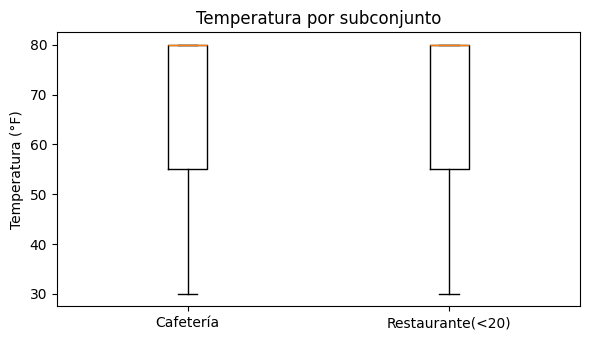

Cafetería - categorías con menos de 40 casos:
  estado_civil: {'Viudo(a)': 37}
  educacion: {'Bachillerato incompleto': 28}
  ocupacion: {'Producción': 28, 'Limpieza y Mantenimiento de Edificios': 11, 'Agricultura, Pesca y Silvicultura': 11}
Restaurante(<20) - categorías con menos de 40 casos:
  estado_civil: {'Viudo(a)': 29}
  educacion: {'Bachillerato incompleto': 18}
  ocupacion: {'Arquitectura e Ingeniería': 39, 'Cuidado Personal y Servicios': 38, 'Servicios de Protección y Seguridad': 38, 'Ciencias Naturales y Sociales': 36, 'Construcción y Extracción': 35, 'Instalación, Mantenimiento y Reparación': 27, 'Producción': 25, 'Limpieza y Mantenimiento de Edificios': 10, 'Agricultura, Pesca y Silvicultura': 7}


In [11]:
# Estadisticas descriptivas por subconjunto. La unica variable numerica es temperatura, para las
# categoricas describe muestra cuantas categorias hay, la mas frecuente y cuantas veces aparece
for tipo, df in subconjuntos.items():
    print(f"===== {tipo} =====")
    print("Valores de temperatura:", df["temperatura"].value_counts().sort_index().to_dict())
    display(df[["temperatura"]].describe().T.round(2))
    display(df.drop(columns="temperatura").describe().T)

# Boxplot de temperatura para buscar valores atipicos
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.boxplot([df["temperatura"] for df in subconjuntos.values()], labels=TIPOS)
ax.set_ylabel("Temperatura (°F)")
ax.set_title("Temperatura por subconjunto")
plt.tight_layout()
plt.show()

# En variables categoricas lo mas parecido a un atipico son categorias con muy pocos casos
for tipo, df in subconjuntos.items():
    print(f"{tipo} - categorías con menos de 40 casos:")
    for col in ["estado_civil", "educacion", "ocupacion"]:
        conteo = df[col].value_counts()
        print(f"  {col}: {conteo[conteo < 40].to_dict()}")

### Resumen de calidad por dimensión

| Dimensión | Qué encontramos | Qué hacemos |
|---|---|---|
| Completitud | `vehiculo` está vacía en el 99% de las filas (solo 37 y 25 tienen dato). Las cinco frecuencias tienen entre 0.8% y 1.8% de faltantes. El resto de columnas está completo. | Eliminar `vehiculo` e imputar las frecuencias con la moda dentro del pipeline |
| Unicidad | 7 duplicados exactos en cada subconjunto, y 4 (Cafetería) y 3 (Restaurante) filas con las mismas características pero etiqueta distinta | Quitar los duplicados exactos y dejar los de etiqueta distinta, que son ruido propio del problema |
| Consistencia | No hay categorías mal escritas ni con mayúsculas o espacios distintos, todas coinciden con el diccionario. Las relaciones lógicas se cumplen (`misma_direccion` y `direccion_opuesta` siempre son contrarias, y más de 25 min siempre implica más de 15 min) | No hay valores que corregir, pero sí quitar la información repetida |
| Validez | `temperatura` solo toma 30, 55 y 80 °F, todos valores posibles. Ninguna categoría está por fuera de las que define el diccionario | Nada que corregir |

Sobre **valores atípicos**: la única variable numérica es temperatura y solo tiene tres valores posibles, entonces no hay atípicos en el sentido clásico (en el boxplot no aparece ningún punto por fuera de los bigotes). En las categóricas lo más parecido son categorías con muy pocos casos, como viudo(a) (37 en Cafetería y 29 en Restaurante), bachillerato incompleto (28 y 18) u ocupaciones como agricultura (11 y 7). No las eliminamos porque son personas reales y no errores, pero esto tiene dos implicaciones para el modelado: el modelo va a aprender muy poco de esos grupos (lo retomamos en la sección de sesgo) y el one-hot tiene que tolerar categorías que no aparezcan en algún fold de entrenamiento, por eso usamos `handle_unknown="ignore"`.

In [12]:
distribucion = pd.DataFrame({
    tipo: df["acepta_cupon"].value_counts() for tipo, df in subconjuntos.items()
}).T
distribucion["% Sí"] = (distribucion["Sí"] / distribucion.sum(axis=1) * 100).round(1)
distribucion["% No"] = (100 - distribucion["% Sí"]).round(1)
distribucion

acepta_cupon,No,Sí,% Sí,% No
Cafetería,1997,1989,49.9,50.1
Restaurante(<20),814,1962,70.7,29.3


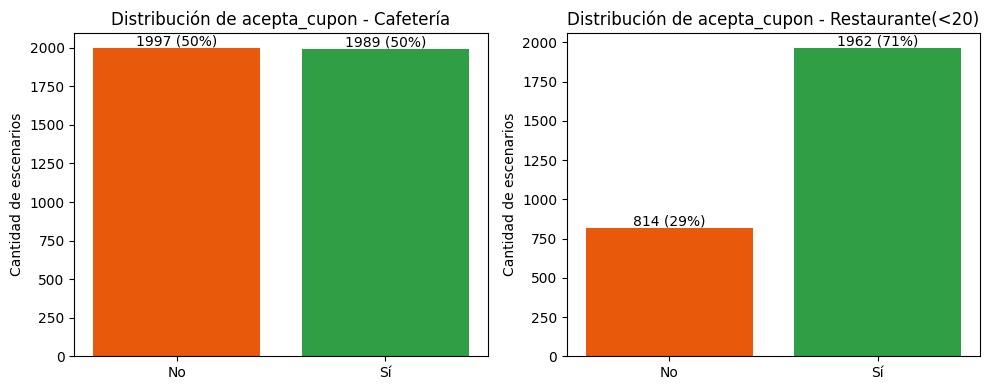

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (tipo, df) in zip(axes, subconjuntos.items()):
    conteo = df["acepta_cupon"].value_counts().reindex(["No", "Sí"])
    ax.bar(conteo.index, conteo.values, color=["#E8590C", "#2F9E44"])
    for i, v in enumerate(conteo.values):
        ax.text(i, v + 20, f"{v} ({v / conteo.sum():.0%})", ha="center")
    ax.set_title(f"Distribución de acepta_cupon - {tipo}")
    ax.set_ylabel("Cantidad de escenarios")
plt.tight_layout()
plt.show()

La distribución de la variable objetivo es muy distinta entre los dos cupones:

- En **Cafetería** las clases están perfectamente balanceadas (49.9% Sí, 50.1% No).
- En **Restaurante(<20)** hay desbalance: 70.7% acepta y solo 29.3% no acepta. Ojo que acá la clase minoritaria es **"No"**, o sea los rechazos. Esto importa bastante porque un modelo que diga "Sí" a todo ya acierta el 70% de las veces sin aprender nada, y por eso la actividad 6 se enfoca en el recall de la clase minoritaria.

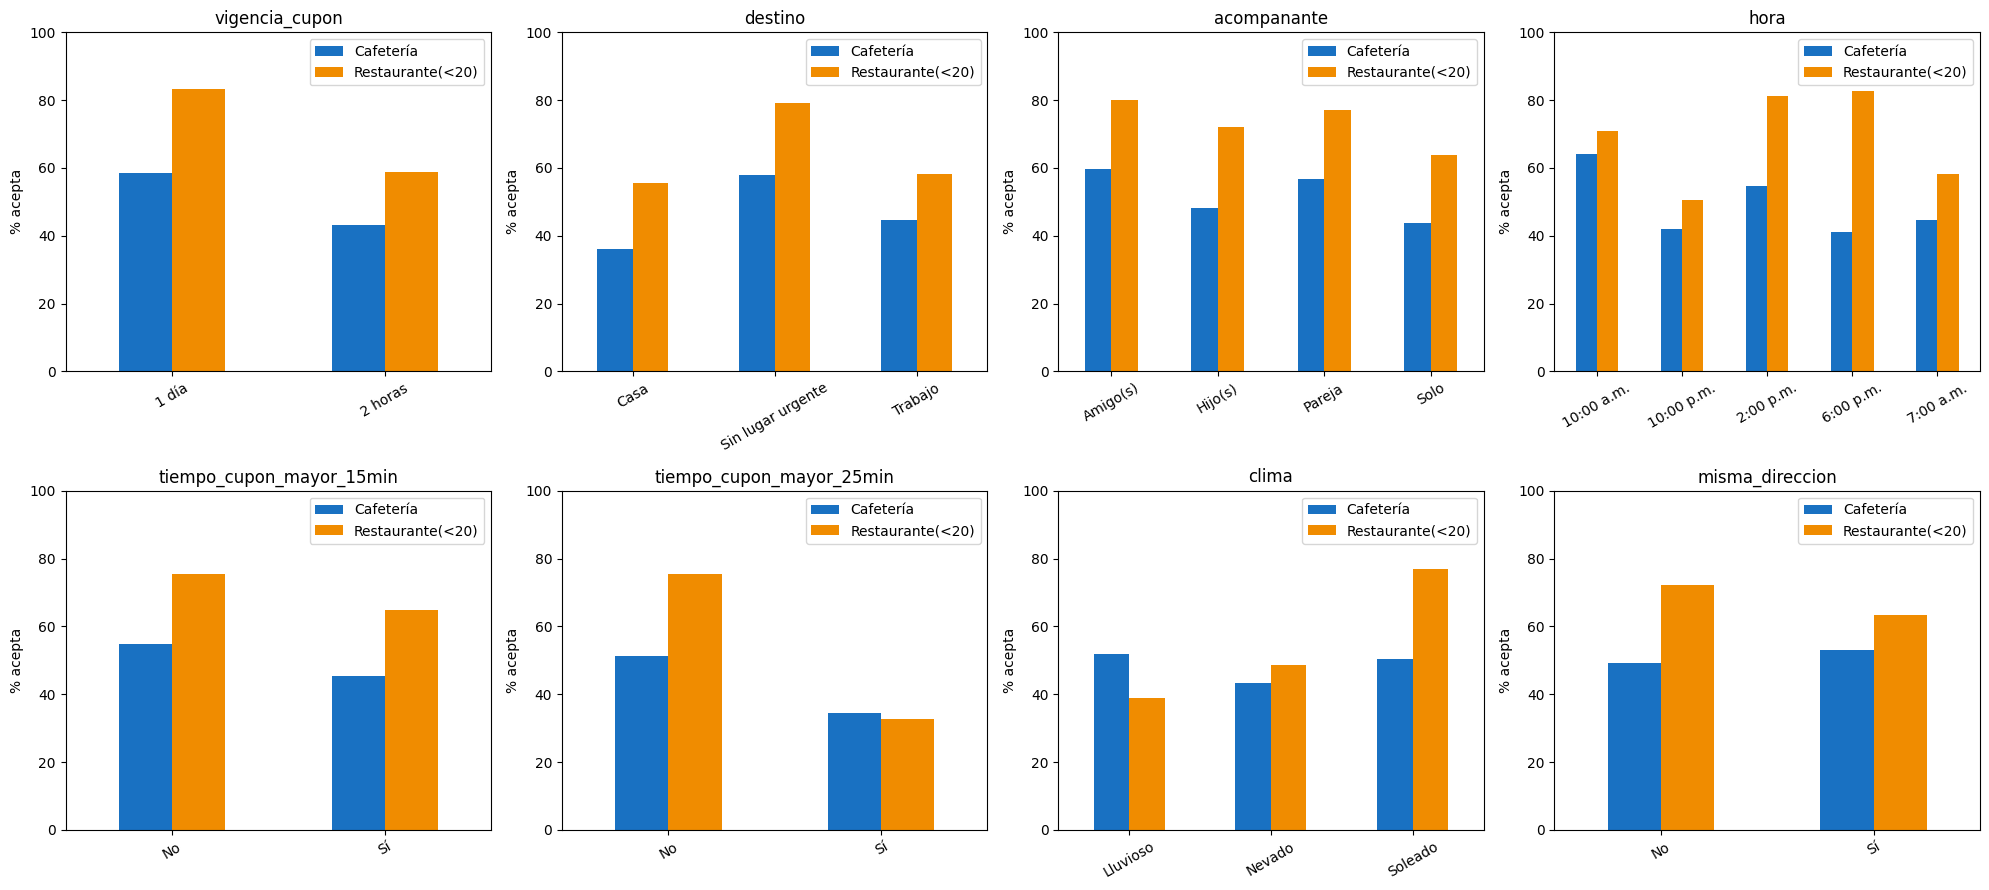

In [14]:
# Tasa de aceptacion (% de "Sí") segun algunas variables de contexto, para cada cupon
def tasa_aceptacion(df, col):
    return df.groupby(col)["acepta_cupon"].apply(lambda s: (s == "Sí").mean() * 100)

variables_contexto = ["vigencia_cupon", "destino", "acompanante", "hora",
                      "tiempo_cupon_mayor_15min", "tiempo_cupon_mayor_25min", "clima", "misma_direccion"]

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, col in zip(axes.ravel(), variables_contexto):
    tabla = pd.DataFrame({tipo: tasa_aceptacion(df, col) for tipo, df in subconjuntos.items()})
    tabla.plot(kind="bar", ax=ax, color=["#1971C2", "#F08C00"], rot=30)
    ax.set_title(col)
    ax.set_ylabel("% acepta")
    ax.set_xlabel("")
    ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

Algunas cosas que se ven en las tasas de aceptación según el contexto:

- **vigencia_cupon** es de las más claras en los dos casos: con vigencia de 1 día se acepta mucho más que con 2 horas (58.4% vs 43.2% en Cafetería, 83.2% vs 58.9% en Restaurante).
- **destino**: cuando el conductor va "Sin lugar urgente" acepta mucho más (58% en Cafetería, 79% en Restaurante) que cuando va para la casa (36% y 56%).
- **acompañante**: ir con amigos sube la aceptación y manejar solo la baja en los dos cupones.
- **hora**: en Cafetería el mejor momento es a las 10 a.m. (64%), y en Restaurante es a las 2 p.m. y 6 p.m. (81% y 83%), o sea a la hora de almuerzo y comida, lo que tiene todo el sentido.
- **distancia**: si el lugar queda a más de 25 minutos la aceptación se cae, sobre todo en Restaurante (de 75.5% a 32.6%).
- **clima**: en Restaurante pesa bastante (76.8% con sol vs 38.8% con lluvia), en Cafetería casi no cambia.
- **misma_direccion** se comporta raro en Restaurante (se acepta menos cuando queda en la misma dirección). Creemos que esto es por confusión con destino: todos los viajes "Sin lugar urgente", que son los que más aceptan, tienen misma_direccion = "No".

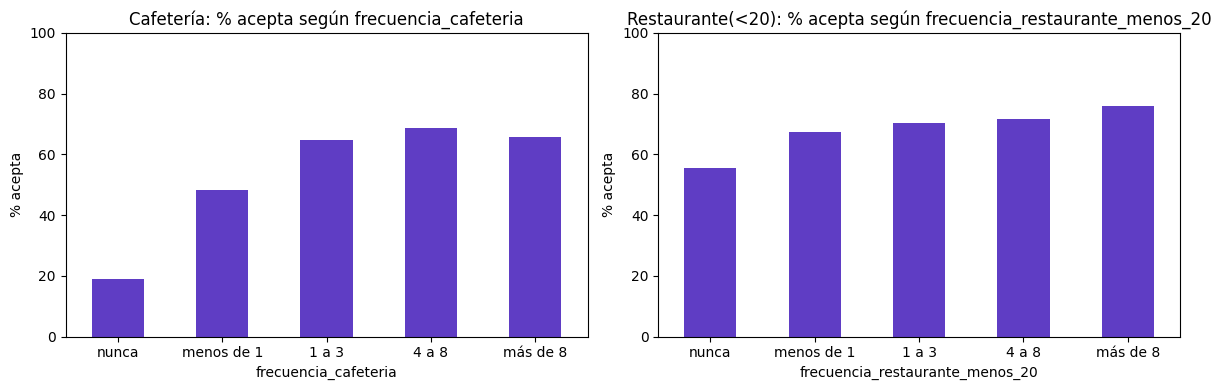

In [15]:
# Tasa de aceptacion segun la frecuencia con la que el conductor visita ese tipo de lugar
orden_frec = ["nunca", "menos de 1", "1 a 3", "4 a 8", "más de 8"]
habito = {"Cafetería": "frecuencia_cafeteria", "Restaurante(<20)": "frecuencia_restaurante_menos_20"}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (tipo, df) in zip(axes, subconjuntos.items()):
    tasa_aceptacion(df, habito[tipo]).reindex(orden_frec).plot(kind="bar", ax=ax, color="#5F3DC4", rot=0)
    ax.set_title(f"{tipo}: % acepta según {habito[tipo]}")
    ax.set_ylabel("% acepta")
    ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

El hábito del conductor es clave en Cafetería: los que **nunca** van a cafeterías solo aceptan el 18.8% de las veces, mientras que los que van 1 a 3 veces al mes o más aceptan entre 65% y 69%. En Restaurante el efecto existe pero es mucho más suave (55.6% los que nunca van vs 76% los que van más de 8 veces), porque casi todo el mundo come en restaurantes baratos de vez en cuando.

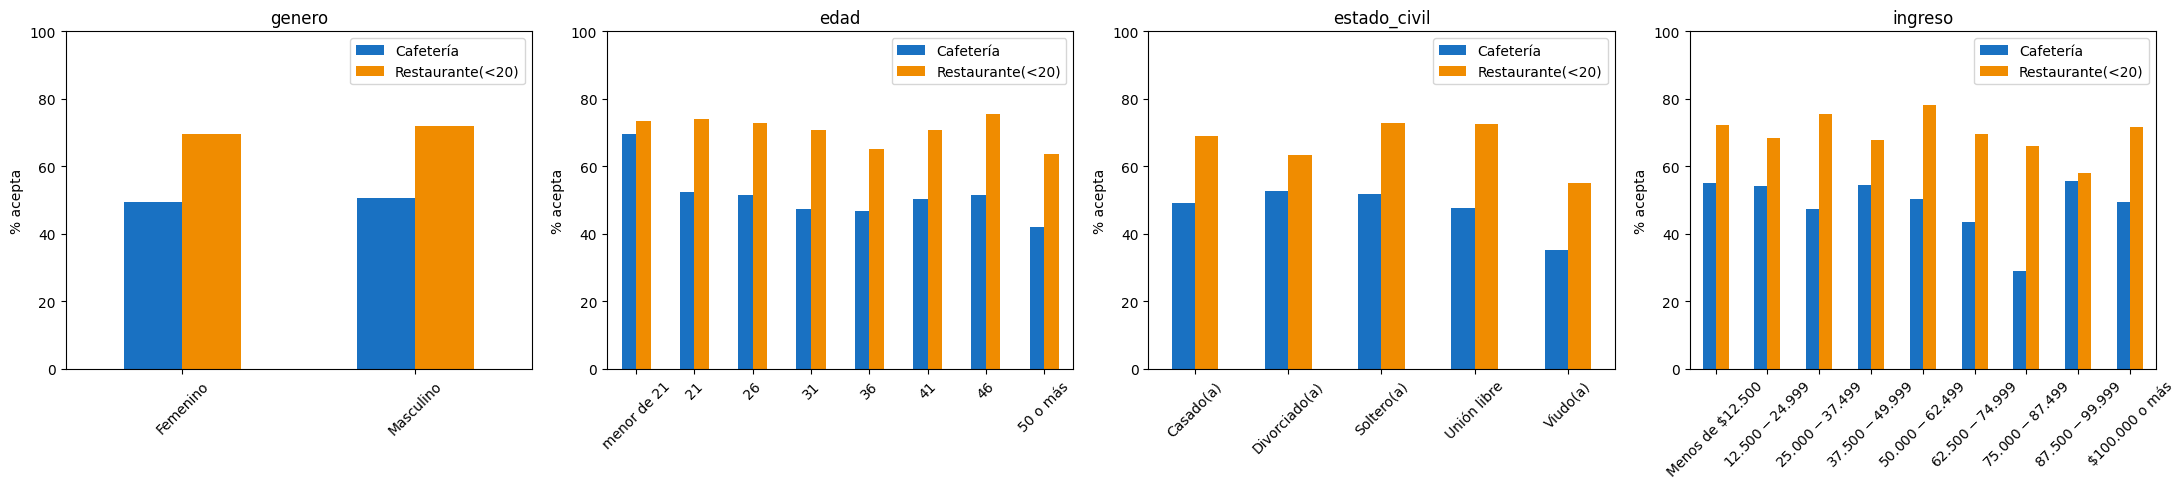

In [16]:
# Tasa de aceptacion segun variables demograficas (las mismas que despues se
# discuten en la seccion de sesgo)
variables_demo = ["genero", "edad", "estado_civil", "ingreso"]
orden_demo = {
    "edad": ["menor de 21", "21", "26", "31", "36", "41", "46", "50 o más"],
    "ingreso": ["Menos de $12.500", "$12.500 - $24.999", "$25.000 - $37.499", "$37.500 - $49.999",
                "$50.000 - $62.499", "$62.500 - $74.999", "$75.000 - $87.499", "$87.500 - $99.999",
                "$100.000 o más"],
}

fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, col in zip(axes, variables_demo):
    tabla = pd.DataFrame({tipo: tasa_aceptacion(df, col) for tipo, df in subconjuntos.items()})
    if col in orden_demo:
        tabla = tabla.reindex(orden_demo[col])
    tabla.plot(kind="bar", ax=ax, color=["#1971C2", "#F08C00"], rot=45)
    ax.set_title(col)
    ax.set_ylabel("% acepta")
    ax.set_xlabel("")
    ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

Las variables demográficas muestran diferencias más pequeñas que las de contexto. El género casi no cambia nada (49.3% vs 50.5% en Cafetería y 69.6% vs 71.8% en Restaurante). En edad, los menores de 21 aceptan bastante más el cupón de Cafetería (69.7%) y los de 50 o más aceptan menos en los dos cupones. Por estado civil los viudos aceptan menos, pero son muy pocos (130 en todo el archivo), entonces no hay que creerle mucho a ese número. En ingreso no se ve un patrón ordenado, hay saltos raros como el grupo de \$75.000 - \$87.499 que en Cafetería acepta solo el 29%. Esto nos da una primera idea de que el contexto del viaje y los hábitos pesan más que el perfil demográfico, cosa que después confirmamos con los modelos.

## Actividad 2 - Limpieza y preparación de los datos

Con base en lo que encontramos en la exploración, estas son las decisiones de limpieza y preparación:

| Decisión | Justificación |
|---|---|
| Eliminar `vehiculo` | 99% de faltantes, no hay forma de imputarla con sentido |
| Eliminar `tiempo_cupon_mayor_5min` | Es constante (siempre "Sí") |
| Eliminar `cupon` | Es constante dentro de cada subconjunto |
| Eliminar `direccion_opuesta` | Es exactamente lo contrario de `misma_direccion` |
| Reemplazar `tiempo_cupon_mayor_15min` y `tiempo_cupon_mayor_25min` por `distancia_cupon` (0, 1, 2) | Las dos columnas son una sola variable ordinal partida en dos |
| Quitar los duplicados exactos | Son registros repetidos que inflarían el peso de esos casos (y podrían quedar a la vez en train y en test) |
| Dejar los duplicados con etiqueta distinta | No hay forma de saber cuál de las dos etiquetas es la correcta y son muy pocos, son ruido propio del problema |
| Imputar las frecuencias con la moda | Pocos faltantes (< 2%) en variables categóricas, la moda es la opción más sencilla y razonable |
| Codificación ordinal para hora, edad, educación, ingreso y frecuencias | Tienen un orden natural (según el diccionario), entonces se codifican como 0, 1, 2... respetando ese orden |
| One-hot para las nominales (destino, acompañante, clima, vigencia, género, estado civil, hijos, ocupación, misma dirección) | No tienen orden, y en las binarias dejamos una sola columna (`drop="if_binary"`) |
| Estandarizar (solo en regresión logística) | La regularización de la logística es sensible a la escala de las variables, los árboles no la necesitan |

Algo importante es separar lo que se puede hacer antes de partir en train/test de lo que no. Quitar columnas, quitar duplicados y crear `distancia_cupon` son transformaciones fila por fila que no aprenden nada de los datos, entonces se pueden hacer antes. En cambio la imputación (la moda se calcula con los datos), la codificación y el escalado sí aprenden de los datos, entonces van **dentro del pipeline**, para que en la validación cruzada se ajusten solo con los folds de entrenamiento y no haya fuga de información.

In [17]:
# Columnas que se eliminan (ver justificacion arriba)
COLUMNAS_ELIMINAR = ["cupon", "vehiculo", "tiempo_cupon_mayor_5min", "direccion_opuesta",
                     "tiempo_cupon_mayor_15min", "tiempo_cupon_mayor_25min"]

# Orden de las categorias ordinales (tomado del diccionario de datos)
FRECUENCIA = ["nunca", "menos de 1", "1 a 3", "4 a 8", "más de 8"]
ORDEN = {
    "hora": ["7:00 a.m.", "10:00 a.m.", "2:00 p.m.", "6:00 p.m.", "10:00 p.m."],
    "edad": orden_demo["edad"],
    "educacion": ["Bachillerato incompleto", "Bachillerato completo", "Estudios universitarios sin título",
                  "Técnico/Tecnólogo", "Pregrado", "Posgrado (Maestría o Doctorado)"],
    "ingreso": orden_demo["ingreso"],
    "frecuencia_bar": FRECUENCIA,
    "frecuencia_cafeteria": FRECUENCIA,
    "frecuencia_comida_para_llevar": FRECUENCIA,
    "frecuencia_restaurante_menos_20": FRECUENCIA,
    "frecuencia_restaurante_20_a_50": FRECUENCIA,
}
COLS_ORDINALES = list(ORDEN.keys())
COLS_NUMERICAS = ["temperatura", "distancia_cupon"]
COLS_NOMINALES = ["destino", "acompanante", "clima", "vigencia_cupon", "genero", "estado_civil",
                  "tiene_hijos", "ocupacion", "misma_direccion"]


def preparar(df):
    """Transformaciones fila a fila (no aprenden nada de los datos, entonces no generan fuga
    de informacion y se pueden aplicar antes de partir en train/test)."""
    df = df.copy()
    # 0 = menos de 15 min, 1 = entre 15 y 25 min, 2 = mas de 25 min
    df["distancia_cupon"] = ((df["tiempo_cupon_mayor_15min"] == "Sí").astype(int)
                             + (df["tiempo_cupon_mayor_25min"] == "Sí").astype(int))
    return df.drop(columns=[c for c in COLUMNAS_ELIMINAR if c in df.columns])


def crear_preprocesador():
    """Transformaciones que si aprenden de los datos (imputacion y codificacion). Van dentro del
    pipeline para que en la validacion cruzada se ajusten solo con los folds de entrenamiento."""
    ordinales = Pipeline([
        ("codificacion", OrdinalEncoder(categories=[ORDEN[c] for c in COLS_ORDINALES],
                                        handle_unknown="use_encoded_value", unknown_value=np.nan)),
        ("imputacion", SimpleImputer(strategy="most_frequent")),
    ])
    numericas = Pipeline([("imputacion", SimpleImputer(strategy="median"))])
    nominales = Pipeline([
        ("imputacion", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("ordinales", ordinales, COLS_ORDINALES),
        ("numericas", numericas, COLS_NUMERICAS),
        ("nominales", nominales, COLS_NOMINALES),
    ], verbose_feature_names_out=False)

In [18]:
# Para cada cupon: quitamos duplicados exactos, aplicamos la preparacion fila a fila
# y partimos en 80% entrenamiento / 20% test estratificando por la variable objetivo
conjuntos = {}
for tipo, df in subconjuntos.items():
    df = df.drop_duplicates()
    X = preparar(df.drop(columns="acepta_cupon"))
    y = (df["acepta_cupon"] == "Sí").astype(int)   # 1 = acepta, 0 = no acepta
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
    conjuntos[tipo] = {"X": X, "y": y, "X_train": X_tr, "X_test": X_te, "y_train": y_tr, "y_test": y_te}
    print(f"{tipo}: train {X_tr.shape}, test {X_te.shape}, % Sí en train {y_tr.mean():.1%}, % Sí en test {y_te.mean():.1%}")

Cafetería: train (3183, 20), test (796, 20), % Sí en train 49.8%, % Sí en test 49.9%
Restaurante(<20): train (2215, 20), test (554, 20), % Sí en train 70.7%, % Sí en test 70.8%


Partimos cada subconjunto en 80% entrenamiento y 20% test, estratificando por la variable objetivo para que las proporciones de Sí y No queden iguales en las dos partes (se ve que en Restaurante quedó 70.7% de Sí en train y 70.8% en test). El test queda guardado y solo se usa al final para comparar los modelos ya ajustados.

In [19]:
# Verificamos que el preprocesador funciona y vemos cuantas columnas genera
prep = crear_preprocesador().fit(conjuntos["Cafetería"]["X_train"])
columnas_finales = prep.get_feature_names_out()
print("Columnas de entrada:", conjuntos["Cafetería"]["X_train"].shape[1])
print("Columnas despues de codificar:", len(columnas_finales))
pd.DataFrame(prep.transform(conjuntos["Cafetería"]["X_train"].head()), columns=columnas_finales)

Columnas de entrada: 20
Columnas despues de codificar: 55


,hora,edad,educacion,ingreso,frecuencia_bar,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,temperatura,distancia_cupon,destino_Casa,destino_Sin lugar urgente,destino_Trabajo,acompanante_Amigo(s),acompanante_Hijo(s),acompanante_Pareja,acompanante_Solo,clima_Lluvioso,clima_Nevado,clima_Soleado,vigencia_cupon_2 horas,genero_Masculino,estado_civil_Casado(a),estado_civil_Divorciado(a),...,ocupacion_Apoyo Administrativo y de Oficina,ocupacion_Apoyo en Salud,ocupacion_Arquitectura e Ingeniería,"ocupacion_Artes, Diseño, Entretenimiento, Deportes y Medios",ocupacion_Ciencias Naturales y Sociales,ocupacion_Computación y Matemáticas,ocupacion_Construcción y Extracción,ocupacion_Cuidado Personal y Servicios,ocupacion_Desempleado(a),"ocupacion_Educación, Formación y Bibliotecología",ocupacion_Estudiante,ocupacion_Gerencia,"ocupacion_Instalación, Mantenimiento y Reparación",ocupacion_Jubilado(a),ocupacion_Limpieza y Mantenimiento de Edificios,ocupacion_Negocios y Finanzas,ocupacion_Preparación y Servicio de Alimentos,ocupacion_Producción,ocupacion_Profesionales y Técnicos de la Salud,ocupacion_Servicios Comunitarios y Sociales,ocupacion_Servicios de Protección y Seguridad,ocupacion_Transporte y Manejo de Materiales,ocupacion_Ventas y afines,ocupacion_Área Legal,misma_direccion_Sí
0,1.0,2.0,5.0,5.0,3.0,2.0,3.0,3.0,2.0,80.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2.0,4.0,5.0,8.0,2.0,1.0,2.0,3.0,2.0,80.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,2.0,5.0,4.0,8.0,1.0,2.0,2.0,3.0,1.0,80.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.0,2.0,2.0,6.0,0.0,0.0,2.0,3.0,1.0,80.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2.0,1.0,4.0,5.0,0.0,1.0,2.0,1.0,1.0,80.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


El preprocesador pasa de 20 columnas a 55, sobre todo por ocupación que tiene 25 categorías. Las ordinales quedan como números (por ejemplo hora va de 0 = 7 a.m. a 4 = 10 p.m., y las frecuencias de 0 = nunca a 4 = más de 8).

### Métricas y validación cruzada

Para todas las búsquedas usamos la misma validación cruzada estratificada de 5 folds (`StratifiedKFold` con `random_state=42`), para que los resultados de los distintos modelos sean comparables entre sí, igual que hicimos en el Lab 2.

Sobre la métrica para escoger hiperparámetros: el enunciado pide reportar precisión, recall y F1. Al principio usamos el F1 de la clase "Sí" para escoger, pero nos dimos cuenta de un problema en Restaurante(<20): como el 70% de los casos son "Sí", un modelo que diga "Sí" siempre ya saca un F1 de 0.83 sin aprender nada (la celda de abajo lo muestra). De hecho, con ese criterio la búsqueda de regresión logística con SMOTE terminó escogiendo un modelo que predecía "Sí" para todo el mundo. Por eso decidimos escoger los hiperparámetros con el **F1 macro** (el promedio del F1 de las dos clases), que castiga a un modelo que ignora la clase "No". En Cafetería, como las clases están balanceadas, el F1 macro y el F1 de la clase Sí dan casi lo mismo. Igual seguimos reportando el F1, la precisión y el recall de la clase "Sí" (aceptar), y el recall de la clase "No".

In [20]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

metricas = {
    "F1": "f1",                     # F1 de la clase positiva (Sí = acepta)
    "Precision": "precision",
    "Recall": "recall",
    "F1_macro": "f1_macro",         # promedio del F1 de las dos clases
    "Recall_No": make_scorer(recall_score, pos_label=0),   # recall de la clase "No"
}


def buscar_hiperparametros(pipeline, grid, tipo, nombre):
    """GridSearchCV con validacion cruzada estratificada, seleccionando por F1 macro."""
    c = conjuntos[tipo]
    grid_search = GridSearchCV(pipeline, grid, cv=cv, scoring=metricas, refit="F1_macro",
                               n_jobs=-1, return_train_score=True)
    grid_search.fit(c["X_train"], c["y_train"])

    i = grid_search.best_index_
    r = grid_search.cv_results_
    print(f"{nombre} - {tipo}")
    print("  Mejor combinación:", grid_search.best_params_)
    print(f"  F1 macro cv:  {r['mean_test_F1_macro'][i]:.3f} ± {r['std_test_F1_macro'][i]:.3f}   (F1 macro train: {r['mean_train_F1_macro'][i]:.3f})")
    print(f"  F1 (Sí) cv:   {r['mean_test_F1'][i]:.3f}   Precisión cv: {r['mean_test_Precision'][i]:.3f}   Recall cv: {r['mean_test_Recall'][i]:.3f}")
    print(f"  Recall clase No cv: {r['mean_test_Recall_No'][i]:.3f}")
    return grid_search


def resumen_cv(grid_search, nombre, tipo):
    i = grid_search.best_index_
    r = grid_search.cv_results_
    return {
        "Cupón": tipo, "Modelo": nombre,
        "F1_macro_cv": r["mean_test_F1_macro"][i], "F1_macro_cv_std": r["std_test_F1_macro"][i],
        "F1_macro_train": r["mean_train_F1_macro"][i],
        "F1_cv": r["mean_test_F1"][i], "Recall_No_cv": r["mean_test_Recall_No"][i],
    }


def evaluar_en_test(modelo, tipo, nombre):
    c = conjuntos[tipo]
    pred = modelo.predict(c["X_test"])
    y = c["y_test"]
    return {
        "Cupón": tipo, "Modelo": nombre,
        "Precisión": precision_score(y, pred), "Recall": recall_score(y, pred), "F1": f1_score(y, pred),
        "F1_macro": f1_score(y, pred, average="macro"),
        "Recall_No": recall_score(y, pred, pos_label=0), "Precisión_No": precision_score(y, pred, pos_label=0),
        "Accuracy": (pred == y).mean(),
    }


modelos = {tipo: {} for tipo in TIPOS}   # aca vamos guardando los GridSearchCV de cada modelo

In [21]:
# Linea base: un "modelo" que siempre dice que el conductor acepta el cupon
for tipo in TIPOS:
    y = conjuntos[tipo]["y_test"]
    siempre_si = np.ones_like(y)
    print(f"{tipo} - siempre Sí -> F1 (Sí): {f1_score(y, siempre_si):.3f}   "
          f"F1 macro: {f1_score(y, siempre_si, average='macro'):.3f}   Recall No: 0.000")

Cafetería - siempre Sí -> F1 (Sí): 0.666   F1 macro: 0.333   Recall No: 0.000
Restaurante(<20) - siempre Sí -> F1 (Sí): 0.829   F1 macro: 0.414   Recall No: 0.000


Esta es la línea base: decir siempre "Sí" da F1 (Sí) de 0.666 en Cafetería y 0.829 en Restaurante, pero F1 macro de apenas 0.333 y 0.414. Cualquier modelo que valga la pena tiene que superar eso con claridad.

## Actividad 3 - Regresión logística

El pipeline tiene el preprocesador, un `StandardScaler` y la regresión logística. En la búsqueda exploramos el tipo de regularización (L1, L2 y elastic net), el solver y el valor de C (el inverso de la fuerza de regularización, entre 0.001 y 100). Como no todos los solvers soportan todas las regularizaciones, la grilla se arma como una lista de diccionarios con combinaciones válidas: liblinear y saga con L1 y L2, lbfgs y newton-cg solo con L2, y saga con elastic net (probando l1_ratio de 0.25, 0.5 y 0.75). Pusimos `max_iter=5000` porque saga a veces no convergía con el valor por defecto.

In [22]:
valores_C = [0.001, 0.01, 0.1, 1, 10, 100]

# No todas las combinaciones de regularizacion y solver son validas, por eso la grilla se arma
# como una lista de diccionarios (cada uno con combinaciones compatibles)
grid_lr = [
    {"modelo__solver": ["liblinear", "saga"], "modelo__penalty": ["l1", "l2"], "modelo__C": valores_C},
    {"modelo__solver": ["lbfgs", "newton-cg"], "modelo__penalty": ["l2"], "modelo__C": valores_C},
    {"modelo__solver": ["saga"], "modelo__penalty": ["elasticnet"], "modelo__l1_ratio": [0.25, 0.5, 0.75],
     "modelo__C": valores_C},
]


def pipeline_lr():
    return Pipeline([
        ("prep", crear_preprocesador()),
        ("escalado", StandardScaler()),
        ("modelo", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
    ])


for tipo in TIPOS:
    modelos[tipo]["Regresión logística"] = buscar_hiperparametros(pipeline_lr(), grid_lr, tipo, "Regresión logística")
    print()

Regresión logística - Cafetería
  Mejor combinación: {'modelo__C': 0.1, 'modelo__penalty': 'l1', 'modelo__solver': 'saga'}
  F1 macro cv:  0.706 ± 0.023   (F1 macro train: 0.722)
  F1 (Sí) cv:   0.704   Precisión cv: 0.705   Recall cv: 0.702
  Recall clase No cv: 0.709



Regresión logística - Restaurante(<20)
  Mejor combinación: {'modelo__C': 0.001, 'modelo__penalty': 'l2', 'modelo__solver': 'liblinear'}
  F1 macro cv:  0.668 ± 0.022   (F1 macro train: 0.679)
  F1 (Sí) cv:   0.834   Precisión cv: 0.790   Recall cv: 0.883
  Recall clase No cv: 0.431



In [23]:
# Mejor resultado de validacion cruzada para cada combinacion regularizacion + solver
def tabla_lr(grid_search):
    res = pd.DataFrame(grid_search.cv_results_)
    res["penalty"] = res["param_modelo__penalty"].astype(str)
    res["solver"] = res["param_modelo__solver"].astype(str)
    mejores = res.loc[res.groupby(["penalty", "solver"])["mean_test_F1_macro"].idxmax()]
    return mejores[["penalty", "solver", "param_modelo__C", "param_modelo__l1_ratio",
                    "mean_test_F1_macro", "std_test_F1_macro", "mean_train_F1_macro", "mean_test_Recall_No"]].rename(columns={
        "param_modelo__C": "C", "param_modelo__l1_ratio": "l1_ratio", "mean_test_F1_macro": "F1_macro_cv",
        "std_test_F1_macro": "F1_macro_cv_std", "mean_train_F1_macro": "F1_macro_train",
        "mean_test_Recall_No": "Recall_No_cv"
    }).sort_values("F1_macro_cv", ascending=False).round(4)


for tipo in TIPOS:
    print(tipo)
    display(tabla_lr(modelos[tipo]["Regresión logística"]))

Cafetería


,penalty,solver,C,l1_ratio,F1_macro_cv,F1_macro_cv_std,F1_macro_train,Recall_No_cv
9,l1,saga,0.10,NaN,0.7056,0.0228,0.7223,0.7088
27,l2,newton-cg,0.01,NaN,0.7049,0.0214,0.7200,0.7044
7,l2,saga,0.01,NaN,0.7046,0.0210,0.7201,0.7044
6,l2,liblinear,0.01,NaN,0.7046,0.0214,0.7199,0.7038
26,l2,lbfgs,0.01,NaN,0.7043,0.0209,0.7202,0.7038
44,elasticnet,saga,0.10,0.75,0.7040,0.0223,0.7227,0.7051
8,l1,liblinear,0.10,NaN,0.7031,0.0232,0.7224,0.7032


Restaurante(<20)


,penalty,solver,C,l1_ratio,F1_macro_cv,F1_macro_cv_std,F1_macro_train,Recall_No_cv
2,l2,liblinear,0.001,NaN,0.6680,0.0218,0.6787,0.4306
30,l2,lbfgs,1.000,NaN,0.6586,0.0157,0.6639,0.3766
45,elasticnet,saga,1.000,0.25,0.6586,0.0157,0.6639,0.3766
31,l2,newton-cg,1.000,NaN,0.6586,0.0157,0.6646,0.3766
15,l2,saga,1.000,NaN,0.6586,0.0157,0.6646,0.3766
17,l1,saga,10.000,NaN,0.6582,0.0159,0.6656,0.3766
16,l1,liblinear,10.000,NaN,0.6582,0.0159,0.6655,0.3766


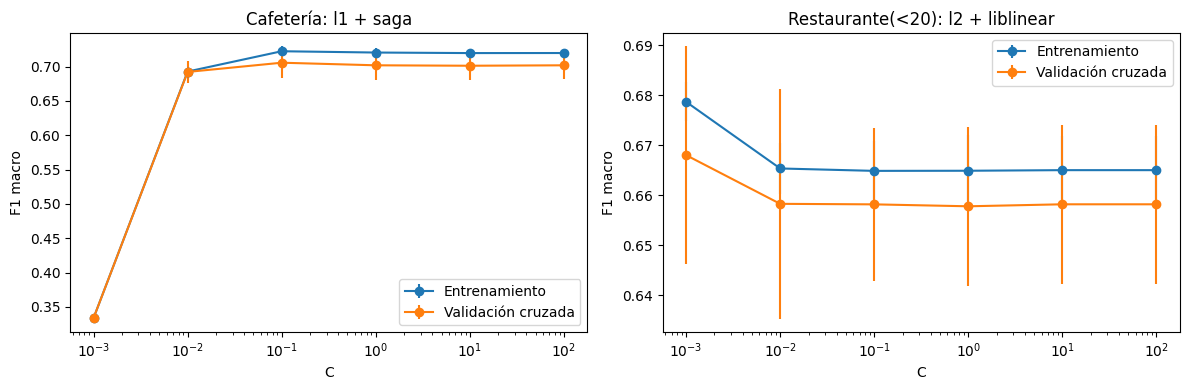

Cafetería


,C,F1_macro_train,F1_macro_cv,Recall_No_cv
1,0.001,0.334,0.334,0.800
5,0.010,0.693,0.692,0.711
9,0.100,0.722,0.706,0.709
13,1.000,0.720,0.702,0.708
17,10.000,0.720,0.701,0.708
21,100.000,0.720,0.702,0.709


Restaurante(<20)


,C,F1_macro_train,F1_macro_cv,Recall_No_cv
2,0.001,0.679,0.668,0.431
6,0.010,0.665,0.658,0.378
10,0.100,0.665,0.658,0.377
14,1.000,0.665,0.658,0.377
18,10.000,0.665,0.658,0.377
22,100.000,0.665,0.658,0.377


In [24]:
# Efecto de C (inverso de la fuerza de regularizacion) en el F1, con el mejor solver/penalty de cada cupon
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, tipo in zip(axes, TIPOS):
    gs = modelos[tipo]["Regresión logística"]
    res = pd.DataFrame(gs.cv_results_)
    mejor = gs.best_params_
    filtro = (res["param_modelo__penalty"] == mejor["modelo__penalty"]) & (res["param_modelo__solver"] == mejor["modelo__solver"])
    if "modelo__l1_ratio" in mejor:
        filtro &= res["param_modelo__l1_ratio"] == mejor["modelo__l1_ratio"]
    sub = res[filtro].sort_values("param_modelo__C")
    C = sub["param_modelo__C"].astype(float)
    ax.errorbar(C, sub["mean_train_F1_macro"], yerr=sub["std_train_F1_macro"], marker="o", label="Entrenamiento")
    ax.errorbar(C, sub["mean_test_F1_macro"], yerr=sub["std_test_F1_macro"], marker="o", label="Validación cruzada")
    ax.set_xscale("log")
    ax.set_xlabel("C")
    ax.set_ylabel("F1 macro")
    ax.set_title(f"{tipo}: {mejor['modelo__penalty']} + {mejor['modelo__solver']}")
    ax.legend()
plt.tight_layout()
plt.show()

# Mismos valores de la grafica en tabla
for tipo in TIPOS:
    gs = modelos[tipo]["Regresión logística"]
    res = pd.DataFrame(gs.cv_results_)
    mejor = gs.best_params_
    filtro = (res["param_modelo__penalty"] == mejor["modelo__penalty"]) & (res["param_modelo__solver"] == mejor["modelo__solver"])
    print(tipo)
    display(res[filtro].sort_values("param_modelo__C")[["param_modelo__C", "mean_train_F1_macro", "mean_test_F1_macro", "mean_test_Recall_No"]]
            .rename(columns={"param_modelo__C": "C", "mean_train_F1_macro": "F1_macro_train",
                             "mean_test_F1_macro": "F1_macro_cv", "mean_test_Recall_No": "Recall_No_cv"}).round(3))

En **Cafetería** la mejor combinación fue L1 con saga y C=0.1, con un F1 macro en validación cruzada de 0.706 (± 0.023). Lo interesante es que todas las combinaciones de regularización y solver quedaron prácticamente empatadas (entre 0.703 y 0.706), o sea que acá el solver casi no importa, lo que importa es escoger bien C. La L1 llevó 12 de las 55 columnas a cero (se ve más adelante en la actividad 8), lo que ayuda a simplificar el modelo sin perder desempeño. El F1 de entrenamiento (0.722) y el de validación (0.706) están cerca, entonces no hay sobreajuste, el modelo más bien se queda corto (es lineal y el problema tiene interacciones).

En **Restaurante(<20)** la mejor fue L2 con liblinear y C=0.001, con F1 macro de 0.668 (± 0.022), bastante por encima de las demás (0.659). Al principio nos pareció raro que ganara una regularización tan fuerte, pero tiene una explicación: liblinear, a diferencia de los otros solvers, también penaliza el intercepto, entonces con un C tan pequeño el intercepto se encoge hacia cero y el modelo empieza a predecir más "No" que lo que diría la proporción de los datos. Eso le sube el recall de la clase No (0.43 vs 0.38 de los demás) y con eso el F1 macro. En la práctica es como mover el umbral de decisión, que es justo lo que ayuda cuando hay desbalance.

La gráfica de C se comporta distinto en los dos cupones. En Cafetería, con C=0.001 la L1 es tan fuerte que elimina casi todas las variables y el F1 macro cae a 0.33, que es lo mismo que predecir una sola clase. Con C=0.01 ya sube a 0.69, el mejor punto está en C=0.1 (0.706) y de ahí en adelante las curvas de train y validación quedan planas, así que más allá de eso ya no cambia nada. En Restaurante pasa al revés: el mejor punto es justo C=0.001, por el efecto del intercepto que explicamos arriba, y desde C=0.01 todo queda plano en 0.658.

## Actividad 4 - Árboles de decisión

El pipeline es el preprocesador y un `DecisionTreeClassifier` (sin escalado porque los árboles no lo necesitan, solo comparan cada variable contra un umbral). La búsqueda explora la profundidad máxima (de 2 a 15 y sin límite), el número mínimo de muestras por hoja (1, 5, 10, 20 y 40) y el criterio de división (gini y entropy).

In [25]:
grid_dt = {
    "modelo__criterion": ["gini", "entropy"],
    "modelo__max_depth": [2, 3, 4, 5, 6, 8, 10, 15, None],
    "modelo__min_samples_leaf": [1, 5, 10, 20, 40],
}


def pipeline_dt():
    return Pipeline([
        ("prep", crear_preprocesador()),
        ("modelo", DecisionTreeClassifier(random_state=RANDOM_STATE)),
    ])


for tipo in TIPOS:
    modelos[tipo]["Árbol de decisión"] = buscar_hiperparametros(pipeline_dt(), grid_dt, tipo, "Árbol de decisión")
    print()

Árbol de decisión - Cafetería
  Mejor combinación: {'modelo__criterion': 'entropy', 'modelo__max_depth': 5, 'modelo__min_samples_leaf': 40}
  F1 macro cv:  0.713 ± 0.014   (F1 macro train: 0.724)
  F1 (Sí) cv:   0.716   Precisión cv: 0.707   Recall cv: 0.725
  Recall clase No cv: 0.701



Árbol de decisión - Restaurante(<20)
  Mejor combinación: {'modelo__criterion': 'gini', 'modelo__max_depth': 15, 'modelo__min_samples_leaf': 20}
  F1 macro cv:  0.686 ± 0.013   (F1 macro train: 0.714)
  F1 (Sí) cv:   0.839   Precisión cv: 0.800   Recall cv: 0.883
  Recall clase No cv: 0.466



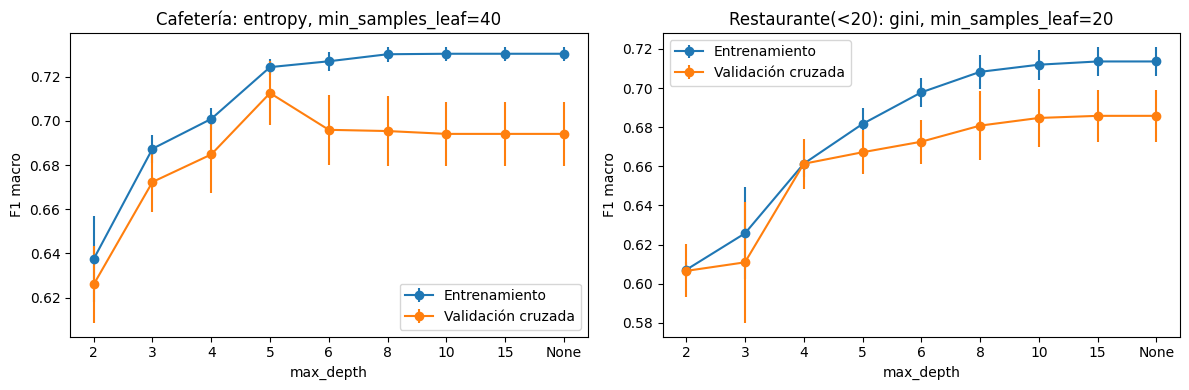

Cafetería


,max_depth,F1_macro_train,F1_macro_cv
49,2,0.637,0.626
54,3,0.687,0.672
59,4,0.701,0.685
64,5,0.724,0.713
69,6,0.727,0.696
74,8,0.730,0.695
79,10,0.730,0.694
84,15,0.730,0.694
89,None,0.730,0.694


Restaurante(<20)


,max_depth,F1_macro_train,F1_macro_cv
3,2,0.607,0.607
8,3,0.626,0.611
13,4,0.661,0.661
18,5,0.682,0.667
23,6,0.698,0.673
28,8,0.708,0.681
33,10,0.712,0.685
38,15,0.714,0.686
43,None,0.714,0.686


In [26]:
# Curva de complejidad: F1 de entrenamiento y de validacion cruzada segun la profundidad maxima,
# dejando fijos el criterio y el min_samples_leaf que gano la busqueda
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, tipo in zip(axes, TIPOS):
    gs = modelos[tipo]["Árbol de decisión"]
    res = pd.DataFrame(gs.cv_results_)
    mejor = gs.best_params_
    sub = res[(res["param_modelo__criterion"] == mejor["modelo__criterion"])
              & (res["param_modelo__min_samples_leaf"] == mejor["modelo__min_samples_leaf"])].copy()
    sub["profundidad"] = sub["param_modelo__max_depth"].apply(lambda d: "None" if pd.isna(d) else str(int(d)))
    ax.errorbar(sub["profundidad"], sub["mean_train_F1_macro"], yerr=sub["std_train_F1_macro"], marker="o", label="Entrenamiento")
    ax.errorbar(sub["profundidad"], sub["mean_test_F1_macro"], yerr=sub["std_test_F1_macro"], marker="o", label="Validación cruzada")
    ax.set_xlabel("max_depth")
    ax.set_ylabel("F1 macro")
    ax.set_title(f"{tipo}: {mejor['modelo__criterion']}, min_samples_leaf={mejor['modelo__min_samples_leaf']}")
    ax.legend()
plt.tight_layout()
plt.show()

# Mismos valores de la grafica en tabla
for tipo in TIPOS:
    gs = modelos[tipo]["Árbol de decisión"]
    res = pd.DataFrame(gs.cv_results_)
    mejor = gs.best_params_
    sub = res[(res["param_modelo__criterion"] == mejor["modelo__criterion"])
              & (res["param_modelo__min_samples_leaf"] == mejor["modelo__min_samples_leaf"])]
    print(tipo)
    display(sub[["param_modelo__max_depth", "mean_train_F1_macro", "mean_test_F1_macro"]]
            .rename(columns={"param_modelo__max_depth": "max_depth", "mean_train_F1_macro": "F1_macro_train",
                             "mean_test_F1_macro": "F1_macro_cv"}).round(3))

In [27]:
# Top 5 combinaciones del arbol para cada cupon
for tipo in TIPOS:
    res = pd.DataFrame(modelos[tipo]["Árbol de decisión"].cv_results_)
    print(tipo)
    display(res.sort_values("rank_test_F1_macro")[["param_modelo__criterion", "param_modelo__max_depth",
                                                   "param_modelo__min_samples_leaf", "mean_test_F1_macro",
                                                   "std_test_F1_macro", "mean_train_F1_macro"]].head(5).round(4))

Cafetería


,param_modelo__criterion,param_modelo__max_depth,param_modelo__min_samples_leaf,mean_test_F1_macro,std_test_F1_macro,mean_train_F1_macro
64,entropy,5,40,0.7126,0.0144,0.7244
19,gini,5,40,0.7103,0.0103,0.7240
16,gini,5,5,0.7091,0.0131,0.7295
15,gini,5,1,0.7085,0.0145,0.7313
17,gini,5,10,0.7065,0.0150,0.7281


Restaurante(<20)


,param_modelo__criterion,param_modelo__max_depth,param_modelo__min_samples_leaf,mean_test_F1_macro,std_test_F1_macro,mean_train_F1_macro
43,gini,None,20,0.6858,0.0131,0.7136
38,gini,15,20,0.6858,0.0131,0.7136
33,gini,10,20,0.6847,0.0149,0.7119
28,gini,8,20,0.6808,0.0174,0.7083
23,gini,6,20,0.6726,0.0113,0.6978


En **Cafetería** el mejor árbol usa entropy, profundidad máxima 5 y mínimo 40 muestras por hoja, con F1 macro en validación de 0.713 (± 0.014), un poquito mejor que la logística. La curva de complejidad muestra el trade-off sesgo-varianza muy parecido a lo que vimos en el Lab 2 con el grado del polinomio: con profundidad 2 o 3 el árbol es muy simple y se queda corto, el mejor punto está en profundidad 5 (0.713), y de ahí para arriba el F1 de entrenamiento sube un poquito más pero el de validación baja a 0.69 y se queda ahí, o sea que el árbol empieza a aprenderse detalles del entrenamiento que no generalizan. No se dispara más porque el min_samples_leaf=40 actúa como freno, no deja hojas con muy pocos casos y por eso a partir de profundidad 8 el árbol ya no crece más.

En **Restaurante(<20)** ganó gini con profundidad 15 y min_samples_leaf=20, con F1 macro de 0.686 (± 0.013). Acá la profundidad casi no importa porque el que frena el crecimiento es el min_samples_leaf: con 20 muestras mínimas por hoja, profundidad 15 y sin límite dan exactamente el mismo árbol (por eso quedan empatados en el top 5). El árbol final tiene 14 niveles reales y 77 hojas, bastante más grande que el de Cafetería. Igual la diferencia entre train (0.714) y validación (0.686) no es tan grande.

## Actividad 5 - Random Forest

Mismo esquema: preprocesador + `RandomForestClassifier`. La búsqueda explora el número de árboles (100, 300, 500), la profundidad máxima (5, 10, 20, sin límite) y el mínimo de muestras por hoja (1, 3, 5). El resto de hiperparámetros los dejamos por defecto (por ejemplo `max_features="sqrt"`, que es lo que hace que cada árbol vea un subconjunto distinto de variables en cada división).

In [28]:
grid_rf = {
    "modelo__n_estimators": [100, 300, 500],
    "modelo__max_depth": [5, 10, 20, None],
    "modelo__min_samples_leaf": [1, 3, 5],
}


def pipeline_rf():
    return Pipeline([
        ("prep", crear_preprocesador()),
        ("modelo", RandomForestClassifier(random_state=RANDOM_STATE)),
    ])


for tipo in TIPOS:
    modelos[tipo]["Random Forest"] = buscar_hiperparametros(pipeline_rf(), grid_rf, tipo, "Random Forest")
    print()

Random Forest - Cafetería
  Mejor combinación: {'modelo__max_depth': 20, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 500}
  F1 macro cv:  0.764 ± 0.003   (F1 macro train: 0.999)
  F1 (Sí) cv:   0.766   Precisión cv: 0.758   Recall cv: 0.775
  Recall clase No cv: 0.753



Random Forest - Restaurante(<20)
  Mejor combinación: {'modelo__max_depth': 20, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 300}
  F1 macro cv:  0.698 ± 0.016   (F1 macro train: 0.999)
  F1 (Sí) cv:   0.854   Precisión cv: 0.800   Recall cv: 0.916
  Recall clase No cv: 0.448



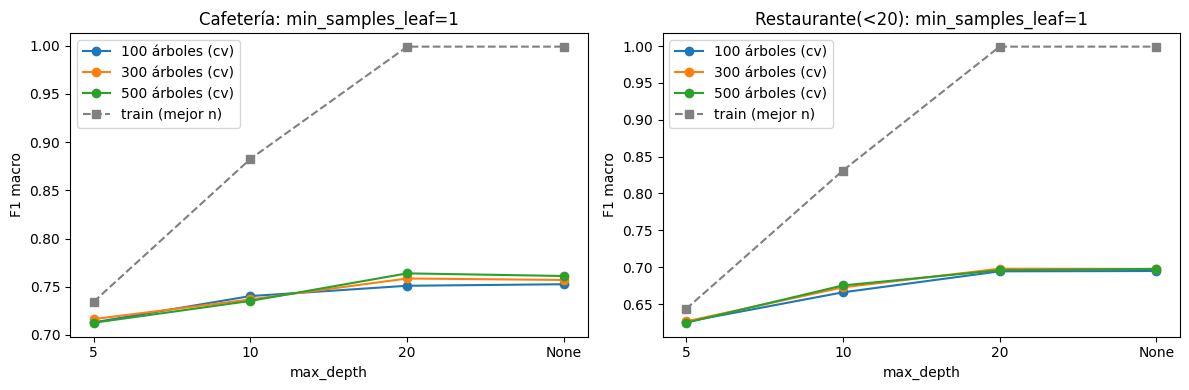

Cafetería


param_modelo__n_estimators,100,300,500
max_depth,,,
5,0.713,0.716,0.713
10,0.740,0.737,0.735
20,0.751,0.759,0.764
None,0.753,0.757,0.761


Restaurante(<20)


param_modelo__n_estimators,100,300,500
max_depth,,,
5,0.626,0.626,0.625
10,0.666,0.673,0.675
20,0.694,0.698,0.696
None,0.695,0.698,0.698


In [29]:
# Efecto de la profundidad y del numero de arboles (con el mejor min_samples_leaf de cada cupon)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, tipo in zip(axes, TIPOS):
    gs = modelos[tipo]["Random Forest"]
    res = pd.DataFrame(gs.cv_results_)
    res = res[res["param_modelo__min_samples_leaf"] == gs.best_params_["modelo__min_samples_leaf"]].copy()
    res["profundidad"] = res["param_modelo__max_depth"].apply(lambda d: "None" if pd.isna(d) else str(int(d)))
    for n, sub in res.groupby("param_modelo__n_estimators"):
        ax.plot(sub["profundidad"], sub["mean_test_F1_macro"], marker="o", label=f"{n} árboles (cv)")
    sub = res[res["param_modelo__n_estimators"] == gs.best_params_["modelo__n_estimators"]]
    ax.plot(sub["profundidad"], sub["mean_train_F1_macro"], marker="s", linestyle="--", color="gray", label="train (mejor n)")
    ax.set_xlabel("max_depth")
    ax.set_ylabel("F1 macro")
    ax.set_title(f"{tipo}: min_samples_leaf={gs.best_params_['modelo__min_samples_leaf']}")
    ax.legend()
plt.tight_layout()
plt.show()

# F1 macro en validacion cruzada por profundidad y numero de arboles (mejor min_samples_leaf)
for tipo in TIPOS:
    gs = modelos[tipo]["Random Forest"]
    res = pd.DataFrame(gs.cv_results_)
    res = res[res["param_modelo__min_samples_leaf"] == gs.best_params_["modelo__min_samples_leaf"]].copy()
    res["max_depth"] = res["param_modelo__max_depth"].apply(lambda d: "None" if pd.isna(d) else str(int(d)))
    print(tipo)
    display(res.pivot(index="max_depth", columns="param_modelo__n_estimators", values="mean_test_F1_macro")
            .reindex(["5", "10", "20", "None"]).round(3))

Random Forest es claramente el mejor de los tres algoritmos. En **Cafetería** la mejor combinación fue 500 árboles, profundidad 20 y min_samples_leaf=1, con F1 macro de 0.764 (± 0.003), unos 5 puntos por encima del árbol solo y con una desviación estándar muchísimo más baja. En **Restaurante(<20)** ganó 300 árboles, profundidad 20 y min_samples_leaf=1, con F1 macro de 0.698 (± 0.016).

Algo que llama la atención es que el F1 de entrenamiento es prácticamente 1 (0.999) en los dos casos, o sea que cada bosque se aprende el entrenamiento casi de memoria, y aun así generaliza mejor que todos los demás modelos. Esto es justo la idea del Random Forest: cada árbol individual tiene mucha varianza (sobreajusta), pero al promediar cientos de árboles entrenados con muestras bootstrap distintas y con subconjuntos de variables distintos, esa varianza se cancela. En la gráfica se ve que la profundidad es lo que más importa: con profundidad 5 los bosques se quedan bastante cortos (0.713 en Cafetería y 0.626 en Restaurante) y el mejor punto está en 20, que da prácticamente lo mismo que sin límite. El número de árboles importa menos, por ejemplo en Cafetería con profundidad 20 pasar de 100 a 500 árboles sube el F1 macro de 0.751 a 0.764, una mejora pequeña pero que se paga con más tiempo de entrenamiento.

Comparado con el árbol individual, la ganancia del bosque depende del cupón. En **Cafetería** es clara: 0.764 contra 0.713 de F1 macro en validación cruzada, 0.784 contra 0.684 en test, y una desviación estándar entre folds mucho menor (0.003 contra 0.014). En **Restaurante(<20)** la ganancia es chica: 0.698 contra 0.686 en validación cruzada y 0.685 contra 0.663 en test, con una variabilidad parecida (0.016 contra 0.013). Creemos que es porque en Restaurante no hay una variable que separe bien las clases y el desbalance limita a los dos modelos por igual, entonces promediar árboles reduce la varianza pero no arregla ese problema de fondo.

## Actividad 6 - Balanceo de clases con SMOTE en Restaurante(<20)

¿Por qué el desbalance podría afectar? Con una proporción 70/30, un modelo que minimiza el error total puede inclinarse hacia el "Sí" y aun así verse bien, porque equivocarse en los "No" pesa poco en la cuenta global. Eso es justo lo que vimos en las actividades 3 a 5: los tres modelos sin balancear detectan menos de la mitad de los rechazos (recall de la clase No entre 0.39 y 0.43 en test).

Para ver si balancear las clases ayuda, repetimos las tres búsquedas exactamente con las mismas grillas, pero ahora agregando SMOTE dentro de un pipeline de `imblearn`. Esto es importante: SMOTE se tiene que aplicar **solo sobre los datos de entrenamiento** de cada fold, porque si se balancea antes de la validación cruzada, los ejemplos sintéticos (que se generan interpolando entre vecinos) terminan filtrándose en los folds de validación y los resultados salen inflados. El pipeline de imblearn se encarga de eso, porque SMOTE solo actúa en el `fit` y no en el `predict`.

SMOTE va después del preprocesador porque necesita trabajar sobre datos numéricos y sin faltantes.

In [30]:
# Mismos tres algoritmos y mismas grillas, pero agregando SMOTE dentro del pipeline de imblearn.
# Asi SMOTE solo se aplica sobre los folds de entrenamiento de la validacion cruzada, nunca sobre
# el fold de validacion ni sobre el test
tipo = "Restaurante(<20)"


def pipeline_smote(modelo, escalar=False):
    pasos = [("prep", crear_preprocesador()), ("smote", SMOTE(random_state=RANDOM_STATE))]
    if escalar:
        pasos.append(("escalado", StandardScaler()))
    pasos.append(("modelo", modelo))
    return ImbPipeline(pasos)


modelos_smote = {
    "Regresión logística + SMOTE": buscar_hiperparametros(
        pipeline_smote(LogisticRegression(max_iter=5000, random_state=RANDOM_STATE), escalar=True),
        grid_lr, tipo, "Regresión logística + SMOTE"),
    "Árbol de decisión + SMOTE": buscar_hiperparametros(
        pipeline_smote(DecisionTreeClassifier(random_state=RANDOM_STATE)), grid_dt, tipo, "Árbol de decisión + SMOTE"),
    "Random Forest + SMOTE": buscar_hiperparametros(
        pipeline_smote(RandomForestClassifier(random_state=RANDOM_STATE)), grid_rf, tipo, "Random Forest + SMOTE"),
}

Regresión logística + SMOTE - Restaurante(<20)
  Mejor combinación: {'modelo__C': 0.01, 'modelo__l1_ratio': 0.25, 'modelo__penalty': 'elasticnet', 'modelo__solver': 'saga'}
  F1 macro cv:  0.674 ± 0.020   (F1 macro train: 0.682)
  F1 (Sí) cv:   0.794   Precisión cv: 0.823   Recall cv: 0.767
  Recall clase No cv: 0.600


Árbol de decisión + SMOTE - Restaurante(<20)
  Mejor combinación: {'modelo__criterion': 'gini', 'modelo__max_depth': 2, 'modelo__min_samples_leaf': 1}
  F1 macro cv:  0.665 ± 0.010   (F1 macro train: 0.665)
  F1 (Sí) cv:   0.832   Precisión cv: 0.788   Recall cv: 0.881
  Recall clase No cv: 0.426


Random Forest + SMOTE - Restaurante(<20)
  Mejor combinación: {'modelo__max_depth': 20, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 500}
  F1 macro cv:  0.710 ± 0.010   (F1 macro train: 0.999)
  F1 (Sí) cv:   0.856   Precisión cv: 0.809   Recall cv: 0.909
  Recall clase No cv: 0.480


In [31]:
# Verificamos el efecto de SMOTE sobre el conjunto de entrenamiento (solo para ilustrar)
c = conjuntos[tipo]
X_prep = crear_preprocesador().fit_transform(c["X_train"])
X_bal, y_bal = SMOTE(random_state=RANDOM_STATE).fit_resample(X_prep, c["y_train"])
print("Antes de SMOTE:  ", c["y_train"].value_counts().rename({1: "Sí", 0: "No"}).to_dict())
print("Despues de SMOTE:", pd.Series(y_bal).value_counts().rename({1: "Sí", 0: "No"}).to_dict())

Antes de SMOTE:   {'Sí': 1567, 'No': 648}
Despues de SMOTE: {'No': 1567, 'Sí': 1567}


SMOTE genera ejemplos sintéticos de la clase "No" hasta igualarla con la clase "Sí" (de 648 a 1567 en el entrenamiento completo).

In [32]:
comparacion_smote = []
for nombre in ["Regresión logística", "Árbol de decisión", "Random Forest"]:
    for etiqueta, gs in [(nombre, modelos[tipo][nombre]), (nombre + " + SMOTE", modelos_smote[nombre + " + SMOTE"])]:
        fila = evaluar_en_test(gs.best_estimator_, tipo, etiqueta)
        cvr = resumen_cv(gs, etiqueta, tipo)
        fila.update({"F1_macro_cv": cvr["F1_macro_cv"], "F1_cv": cvr["F1_cv"], "Recall_No_cv": cvr["Recall_No_cv"]})
        comparacion_smote.append(fila)

tabla_smote = pd.DataFrame(comparacion_smote)[["Modelo", "F1_macro_cv", "F1_cv", "Recall_No_cv", "F1_macro", "F1",
                                                "Recall_No", "Precisión_No", "Recall", "Precisión"]]
tabla_smote.round(3)

,Modelo,F1_macro_cv,F1_cv,Recall_No_cv,F1_macro,F1,Recall_No,Precisión_No,Recall,Precisión
0,Regresión logística,0.668,0.834,0.431,0.665,0.833,0.426,0.600,0.883,0.788
1,Regresión logística + SMOTE,0.674,0.794,0.600,0.663,0.783,0.599,0.497,0.750,0.819
2,Árbol de decisión,0.686,0.839,0.466,0.663,0.842,0.389,0.643,0.911,0.783
3,Árbol de decisión + SMOTE,0.665,0.832,0.426,0.604,0.682,0.722,0.413,0.577,0.834
4,Random Forest,0.698,0.854,0.448,0.685,0.856,0.401,0.714,0.934,0.790
5,Random Forest + SMOTE,0.710,0.856,0.480,0.687,0.849,0.432,0.667,0.911,0.795


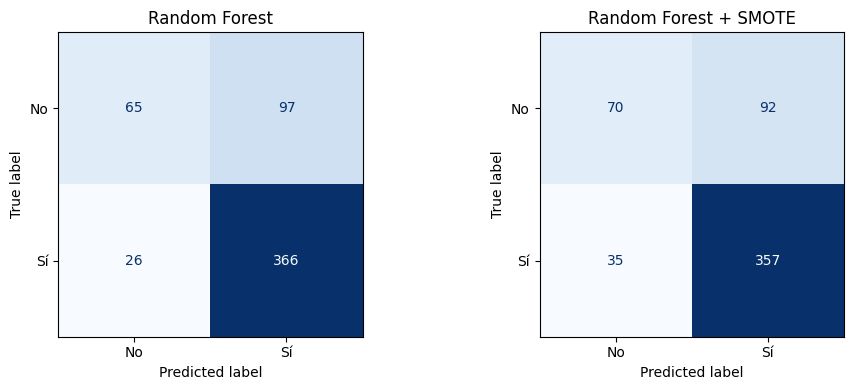

In [33]:
# Matrices de confusion en test: Random Forest sin y con SMOTE
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
c = conjuntos[tipo]
for ax, (etiqueta, modelo) in zip(axes, [("Random Forest", modelos[tipo]["Random Forest"].best_estimator_),
                                         ("Random Forest + SMOTE", modelos_smote["Random Forest + SMOTE"].best_estimator_)]):
    ConfusionMatrixDisplay.from_estimator(modelo, c["X_test"], c["y_test"], display_labels=["No", "Sí"],
                                          ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(etiqueta)
plt.tight_layout()
plt.show()

Comparando cada algoritmo sin y con SMOTE (las columnas de test son sobre el mismo conjunto de test de 554 escenarios):

| Modelo | F1 macro cv | Recall No cv | F1 macro test | F1 (Sí) test | Precisión (Sí) test | Recall (Sí) test | Precisión No test | Recall No test |
|---|---|---|---|---|---|---|---|---|
| Regresión logística | 0.668 | 0.431 | 0.665 | 0.833 | 0.788 | 0.883 | 0.600 | 0.426 |
| Regresión logística + SMOTE | 0.674 | 0.600 | 0.663 | 0.783 | 0.819 | 0.750 | 0.497 | 0.599 |
| Árbol de decisión | 0.686 | 0.466 | 0.663 | 0.842 | 0.783 | 0.911 | 0.643 | 0.389 |
| Árbol de decisión + SMOTE | 0.665 | 0.426 | 0.604 | 0.682 | 0.834 | 0.577 | 0.413 | 0.722 |
| Random Forest | 0.698 | 0.448 | 0.685 | 0.856 | 0.790 | 0.934 | 0.714 | 0.401 |
| Random Forest + SMOTE | 0.710 | 0.480 | 0.687 | 0.849 | 0.795 | 0.911 | 0.667 | 0.432 |

Lo que se repite en los tres algoritmos es que **SMOTE sube el recall de la clase minoritaria (No) en test**: en la logística pasa de 0.43 a 0.60, en el árbol de 0.39 a 0.72 y en Random Forest de 0.40 a 0.43 (en la matriz de confusión se ve que el bosque con SMOTE detecta 70 rechazos de 162 en lugar de 65). A cambio, baja el recall de la clase Sí y con eso el F1 de la clase Sí (de 0.833 a 0.783 en la logística, de 0.842 a 0.682 en el árbol y de 0.856 a 0.849 en Random Forest).

En la logística y en Random Forest el **F1 macro (el F1 general) casi no se mueve**: en validación cruzada sube un poquito (+0.006 y +0.012) y en test queda prácticamente igual (-0.002 y +0.002), diferencias del mismo tamaño que la desviación estándar entre folds. O sea que SMOTE no hace que el modelo "sepa más", lo que hace es mover el punto de equilibrio entre las dos clases: el modelo se vuelve más dispuesto a decir "No".

El árbol es el caso raro. Con SMOTE la búsqueda escogió un árbol de profundidad 2, muy simple, y su F1 macro baja tanto en validación cruzada (0.686 a 0.665) como en test (0.663 a 0.604). Además se comporta muy distinto en validación cruzada (recall No de 0.43) y en test (0.72), lo que muestra que un árbol tan pequeño entrenado sobre datos sintéticos es inestable: cambiar un poco los datos de entrenamiento cambia por completo sus primeras divisiones. Para el árbol SMOTE no sirve.

**El trade-off entre precisión y recall.** Con SMOTE el modelo dice "No" más seguido. Eso hace que detecte más rechazos (sube el recall del No), pero algunos de esos "No" son conductores que sí habrían aceptado, entonces baja la precisión del No (de 0.714 a 0.667 en Random Forest y de 0.600 a 0.497 en la logística). En la clase Sí pasa lo contrario: como el modelo solo dice "Sí" cuando está más seguro, la precisión del Sí sube (de 0.790 a 0.795 en Random Forest y de 0.788 a 0.819 en la logística) y su recall baja (de 0.934 a 0.911 y de 0.883 a 0.750). Llevado al caso, una precisión del Sí más alta quiere decir que una mayor parte de los cupones que se muestran terminan aceptados (menos notificaciones inútiles), y un recall del Sí más bajo quiere decir que se dejan de mostrar algunos cupones que sí se habrían usado. Con Random Forest el costo es pequeño (2 puntos de recall del Sí a cambio de 3 puntos de recall del No), mientras que en la logística y en el árbol el cambio es mucho más brusco.

**Recomendación:** sí conviene aplicar SMOTE, pero junto con Random Forest. Random Forest + SMOTE tiene el mejor F1 macro de todos los modelos de Restaurante, tanto en validación cruzada (0.710) como en test (0.687), detecta más rechazos que sin balancear y casi no pierde F1 en la clase Sí (0.849 vs 0.856). Para Ruta Alpes esto tiene sentido de negocio, porque el enunciado dice que mandar ofertas irrelevantes genera molestia, y la clase "No" es justamente la de los conductores a los que no habría que molestar. Si la prioridad fuera solo maximizar la cantidad de cupones aceptados, el modelo sin balancear (con F1 de la clase Sí un poco más alto) sería igual de válido, la diferencia entre los dos es pequeña. También hay que decir que SMOTE no es la única opción: como trabaja sobre las columnas one-hot, genera valores intermedios (por ejemplo 0.4 en una columna de ocupación) que no corresponden a ninguna persona real. Alternativas como SMOTENC (pensado para variables categóricas), `class_weight="balanced"` o ajustar el umbral de decisión podrían dar resultados parecidos sin inventar datos.

## Actividad 7 - Tabla comparativa sobre test

Juntamos todos los modelos y los evaluamos sobre el conjunto de test, que no se usó para nada en la búsqueda de hiperparámetros. Las columnas de precisión, recall y F1 son de la clase "Sí" (aceptar), y además dejamos el F1 macro y el recall de la clase "No".

In [34]:
filas_test, filas_cv = [], []
for tipo in TIPOS:
    for nombre, gs in modelos[tipo].items():
        filas_test.append(evaluar_en_test(gs.best_estimator_, tipo, nombre))
        filas_cv.append(resumen_cv(gs, nombre, tipo))
for nombre, gs in modelos_smote.items():
    filas_test.append(evaluar_en_test(gs.best_estimator_, "Restaurante(<20)", nombre))
    filas_cv.append(resumen_cv(gs, nombre, "Restaurante(<20)"))

tabla_comparativa = pd.DataFrame(filas_test).merge(pd.DataFrame(filas_cv), on=["Cupón", "Modelo"])
tabla_comparativa = tabla_comparativa[["Cupón", "Modelo", "F1_macro_cv", "F1_macro_cv_std", "F1_macro_train",
                                       "Precisión", "Recall", "F1", "F1_macro", "Recall_No", "Accuracy"]]
tabla_comparativa.round(3)

,Cupón,Modelo,F1_macro_cv,F1_macro_cv_std,F1_macro_train,Precisión,Recall,F1,F1_macro,Recall_No,Accuracy
0,Cafetería,Regresión logística,0.706,0.023,0.722,0.681,0.698,0.689,0.686,0.674,0.686
1,Cafetería,Árbol de decisión,0.713,0.014,0.724,0.664,0.746,0.702,0.684,0.624,0.685
2,Cafetería,Random Forest,0.764,0.003,0.999,0.781,0.788,0.784,0.784,0.779,0.784
3,Restaurante(<20),Regresión logística,0.668,0.022,0.679,0.788,0.883,0.833,0.665,0.426,0.749
4,Restaurante(<20),Árbol de decisión,0.686,0.013,0.714,0.783,0.911,0.842,0.663,0.389,0.758
5,Restaurante(<20),Random Forest,0.698,0.016,0.999,0.790,0.934,0.856,0.685,0.401,0.778
6,Restaurante(<20),Regresión logística + SMOTE,0.674,0.020,0.682,0.819,0.750,0.783,0.663,0.599,0.706
7,Restaurante(<20),Árbol de decisión + SMOTE,0.665,0.010,0.665,0.834,0.577,0.682,0.604,0.722,0.619
8,Restaurante(<20),Random Forest + SMOTE,0.710,0.010,0.999,0.795,0.911,0.849,0.687,0.432,0.771


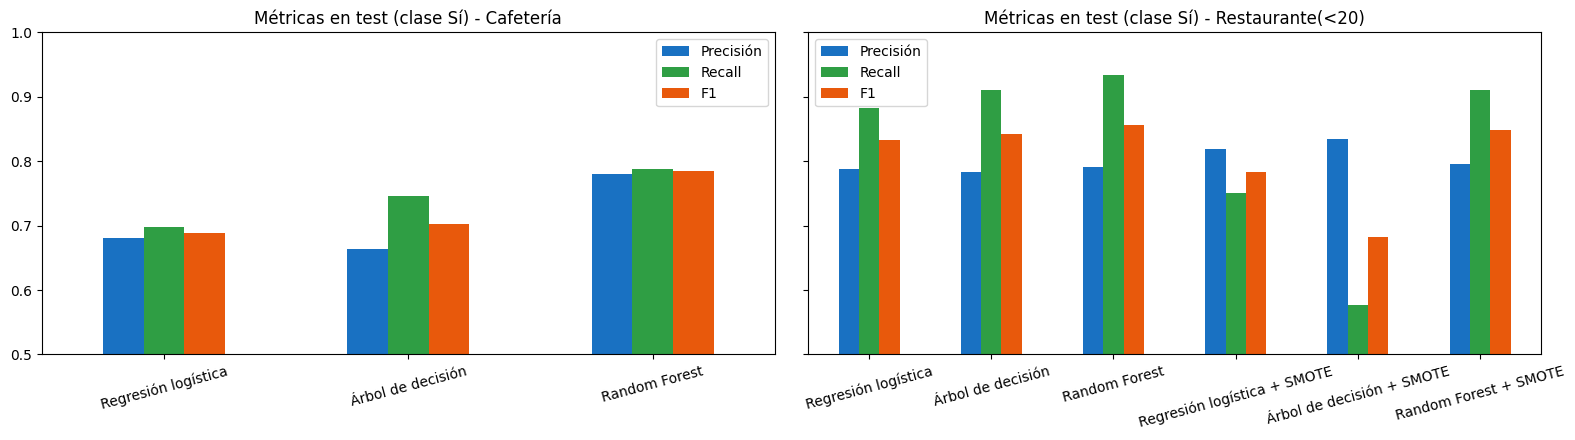

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), sharey=True)
for ax, tipo in zip(axes, TIPOS):
    sub = tabla_comparativa[tabla_comparativa["Cupón"] == tipo].set_index("Modelo")[["Precisión", "Recall", "F1"]]
    sub.plot(kind="bar", ax=ax, rot=15, color=["#1971C2", "#2F9E44", "#E8590C"])
    ax.set_title(f"Métricas en test (clase Sí) - {tipo}")
    ax.set_ylim(0.5, 1)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

**Cafetería** (test, 796 escenarios):

| Modelo | F1 macro cv | Precisión | Recall | F1 | F1 macro | Recall No |
|---|---|---|---|---|---|---|
| Regresión logística | 0.706 ± 0.023 | 0.681 | 0.698 | 0.689 | 0.686 | 0.674 |
| Árbol de decisión | 0.713 ± 0.014 | 0.664 | 0.746 | 0.702 | 0.684 | 0.624 |
| **Random Forest** | **0.764 ± 0.003** | **0.781** | **0.788** | **0.784** | **0.784** | **0.779** |

**Restaurante(<20)** (test, 554 escenarios):

| Modelo | F1 macro cv | Precisión | Recall | F1 | F1 macro | Recall No |
|---|---|---|---|---|---|---|
| Regresión logística | 0.668 ± 0.022 | 0.788 | 0.883 | 0.833 | 0.665 | 0.426 |
| Árbol de decisión | 0.686 ± 0.013 | 0.783 | 0.911 | 0.842 | 0.663 | 0.389 |
| Random Forest | 0.698 ± 0.016 | 0.790 | 0.934 | 0.856 | 0.685 | 0.401 |
| Regresión logística + SMOTE | 0.674 ± 0.020 | 0.819 | 0.750 | 0.783 | 0.663 | 0.599 |
| Árbol de decisión + SMOTE | 0.665 ± 0.010 | 0.834 | 0.577 | 0.682 | 0.604 | 0.722 |
| **Random Forest + SMOTE** | **0.710 ± 0.010** | 0.795 | 0.911 | 0.849 | **0.687** | 0.432 |

En **Cafetería** no hay discusión: Random Forest gana en todo, tanto en validación cruzada como en test, con unos 8 puntos más de F1 que los otros dos (0.784 vs 0.689 y 0.702) y además es el más estable entre folds (std de 0.003). La logística y el árbol quedan muy parecidos entre sí, el árbol tiene más recall y la logística más precisión.

En **Restaurante(<20)** las diferencias son más chiquitas. Escogemos el modelo con el mejor F1 macro en validación cruzada, que es **Random Forest + SMOTE** (0.710), porque esa es la métrica que no "mira" el test. En test también queda primero en F1 macro, aunque por muy poco (0.687 vs 0.685 del Random Forest sin balancear), y el Random Forest sin balancear tiene un F1 de la clase Sí un poco más alto (0.856 vs 0.849). Son diferencias más pequeñas que la variabilidad entre folds, entonces lo que inclina la decisión es lo que se explicó en la actividad 6: el modelo con SMOTE detecta más rechazos, que es lo que sirve para no molestar a los conductores. Los dos Random Forest le ganan a la línea base de "siempre Sí" (F1 macro 0.414) por bastante.

In [36]:
# Mejor modelo por cupon, segun el F1 macro promedio en validacion cruzada (que es el criterio que no
# "mira" el test). Despues confirmamos que tambien sea el mejor (o casi) en test
todos = {tipo: dict(modelos[tipo]) for tipo in TIPOS}
todos["Restaurante(<20)"].update(modelos_smote)

mejor_modelo = {}
for tipo in TIPOS:
    nombre = max(todos[tipo], key=lambda n: todos[tipo][n].best_score_)
    mejor_modelo[tipo] = (nombre, todos[tipo][nombre])
    print(f"{tipo}: {nombre} -> {todos[tipo][nombre].best_params_}")

Cafetería: Random Forest -> {'modelo__max_depth': 20, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 500}
Restaurante(<20): Random Forest + SMOTE -> {'modelo__max_depth': 20, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 500}


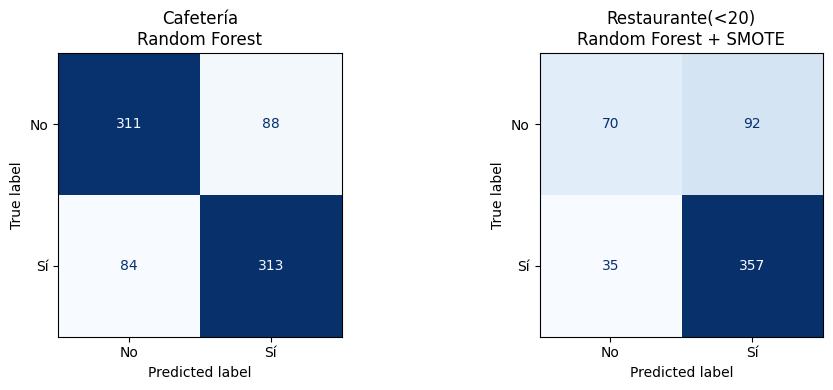

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, tipo in zip(axes, TIPOS):
    nombre, gs = mejor_modelo[tipo]
    c = conjuntos[tipo]
    ConfusionMatrixDisplay.from_estimator(gs.best_estimator_, c["X_test"], c["y_test"],
                                          display_labels=["No", "Sí"], ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{tipo}\n{nombre}")
plt.tight_layout()
plt.show()

En las matrices de confusión se nota la diferencia entre los dos problemas: en Cafetería el modelo se equivoca más o menos igual hacia los dos lados, mientras que en Restaurante el modelo acierta casi todos los "Sí" pero se le escapan más de la mitad de los "No", incluso con SMOTE.

## Actividad 8 - Variables más relevantes

Para identificar las variables más importantes usamos tres miradas distintas, porque cada una tiene sus limitaciones:

1. **Importancia por permutación** sobre el test con el mejor modelo de cada cupón. Consiste en desordenar al azar una variable y ver cuánto empeora el modelo. La ventaja es que se calcula sobre las variables originales (ocupación cuenta como una sola variable aunque genere 25 columnas one-hot) y sirve para cualquier modelo. Como métrica para medir la caída usamos el ROC AUC en lugar del F1, porque probamos con el F1 macro y en Restaurante salían importancias casi todas cercanas a cero o negativas: el F1 depende de un umbral y como el bosque está muy seguro de la mayoría de los "Sí", desordenar una variable casi nunca cambia la predicción final. El AUC mira las probabilidades completas y por eso es más sensible.
2. **Importancia por impureza** del Random Forest (la que trae `feature_importances_`).
3. **Coeficientes de la regresión logística**, que además dicen la dirección del efecto.

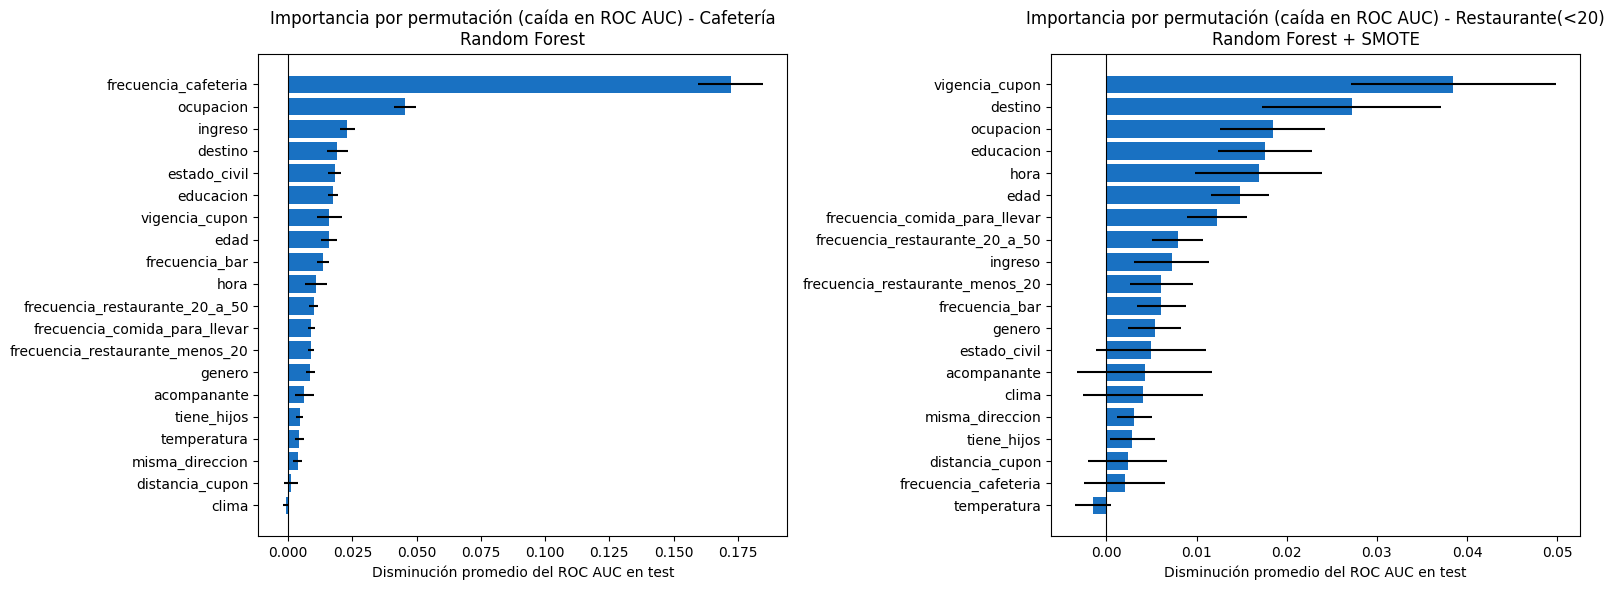

In [38]:
# Importancia por permutacion sobre el test: cuanto cae el ROC AUC si se "desordena" una variable.
# Se calcula sobre las variables originales (antes de codificar), por eso una variable como
# ocupacion cuenta como una sola aunque genere 25 columnas one-hot
importancias = {}
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, tipo in zip(axes, TIPOS):
    nombre, gs = mejor_modelo[tipo]
    c = conjuntos[tipo]
    r = permutation_importance(gs.best_estimator_, c["X_test"], c["y_test"], scoring="roc_auc",
                               n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
    imp = pd.DataFrame({"media": r.importances_mean, "std": r.importances_std},
                       index=c["X_test"].columns).sort_values("media")
    importancias[tipo] = imp
    ax.barh(imp.index, imp["media"], xerr=imp["std"], color="#1971C2")
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"Importancia por permutación (caída en ROC AUC) - {tipo}\n{nombre}")
    ax.set_xlabel("Disminución promedio del ROC AUC en test")
plt.tight_layout()
plt.show()

In [39]:
pd.DataFrame({tipo: imp["media"] for tipo, imp in importancias.items()}).sort_values(
    "Cafetería", ascending=False).round(4)

,Cafetería,Restaurante(<20)
frecuencia_cafeteria,0.1722,0.0020
ocupacion,0.0455,0.0184
ingreso,0.0231,0.0072
destino,0.0192,0.0272
estado_civil,0.0181,0.0049
educacion,0.0174,0.0176
vigencia_cupon,0.0161,0.0385
edad,0.0160,0.0148
frecuencia_bar,0.0136,0.0061
hora,0.0109,0.0169


En **Cafetería** la importancia por permutación confirma lo que se veía en la exploración: frecuencia_cafeteria es lejos la más importante (desordenarla le baja 0.17 al AUC), y después vienen, mucho más abajo, ocupación (0.046), ingreso (0.023), destino (0.019) y luego estado civil, educación, vigencia y edad (entre 0.016 y 0.018). Las que casi no aportan son clima, distancia_cupon, misma_direccion y temperatura (menos de 0.005).

En **Restaurante(<20)** no hay una variable dominante y todas las importancias son más pequeñas. Las primeras son vigencia_cupon (0.039), destino (0.027), ocupación (0.018), educación (0.018), hora (0.017) y edad (0.015). Al final quedan temperatura (que incluso sale negativa), frecuencia_cafeteria, distancia_cupon, tiene_hijos y misma_direccion, todas por debajo de 0.004, y el clima tampoco queda mucho más arriba (0.004). Es curioso que la distancia y el clima salgan tan abajo cuando en la exploración tenían efectos fuertes. Creemos que pasa por dos cosas: la permutación mide lo que aporta cada variable cuando las demás ya están, y clima, temperatura, hora y destino comparten mucha información (si se desordena el clima, el bosque todavía tiene la temperatura), y además solo el 11% de los escenarios de Restaurante está a más de 25 minutos, entonces desordenar esa variable cambia pocas predicciones.

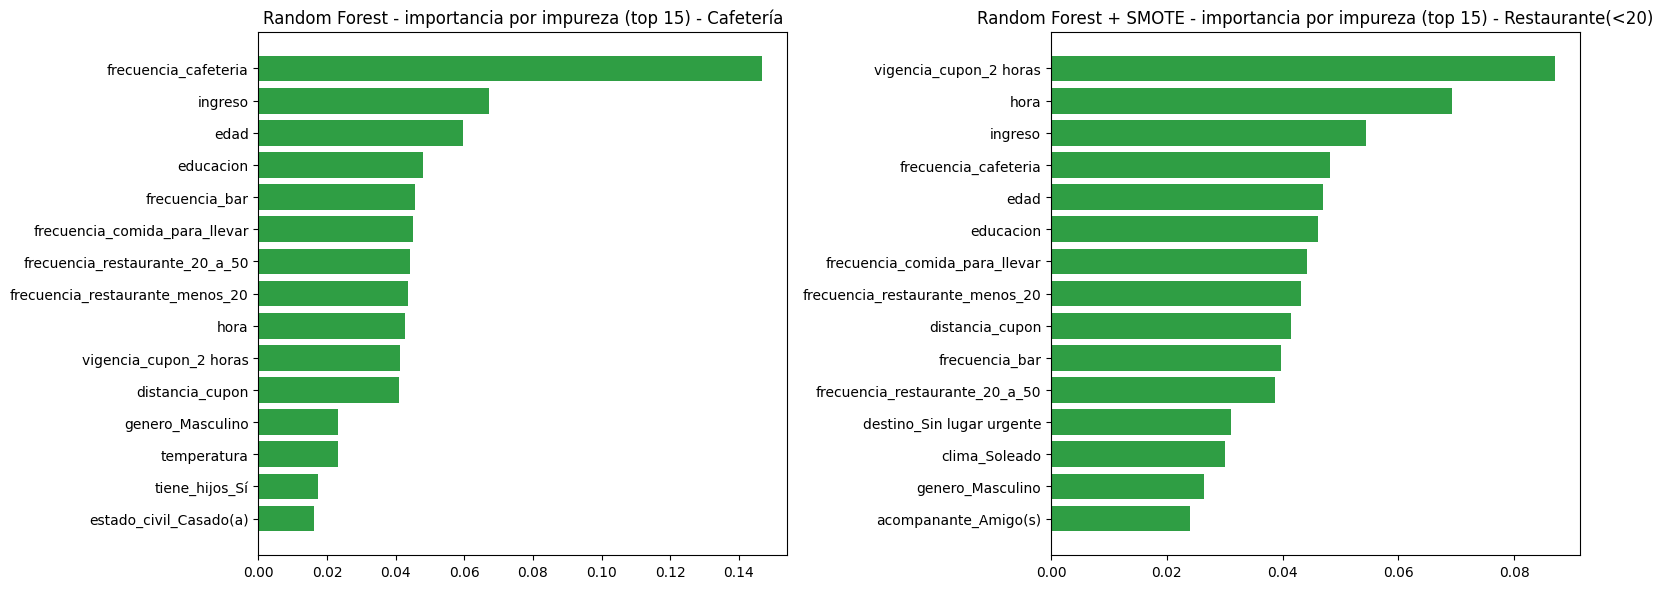

In [40]:
# Importancia por impureza (Gini) del mejor Random Forest de cada cupon, sobre las columnas codificadas
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, tipo in zip(axes, TIPOS):
    pipe = mejor_modelo[tipo][1].best_estimator_
    nombres = pipe.named_steps["prep"].get_feature_names_out()
    imp = pd.Series(pipe.named_steps["modelo"].feature_importances_, index=nombres).sort_values().tail(15)
    ax.barh(imp.index, imp.values, color="#2F9E44")
    ax.set_title(f"{mejor_modelo[tipo][0]} - importancia por impureza (top 15) - {tipo}")
plt.tight_layout()
plt.show()

La importancia por impureza del Random Forest coincide en que **frecuencia_cafeteria** es lejos la variable más importante en Cafetería. Pero hay que tener cuidado con esta medida porque tiene un sesgo conocido: favorece a las variables con muchos valores posibles, como ingreso (9 niveles) o edad (8 niveles), simplemente porque ofrecen más puntos de corte, mientras que las columnas one-hot binarias salen castigadas. Por eso ingreso y edad aparecen arriba en las dos gráficas, cuando en la exploración no mostraban un patrón tan claro. En Restaurante las primeras son vigencia_cupon y hora, que sí coinciden con la exploración. Por ese sesgo le damos más peso a la importancia por permutación.

In [41]:
# Coeficientes de la regresion logistica (variables estandarizadas): el signo dice la direccion
# del efecto sobre la probabilidad de aceptar
coefs = {}
for tipo in TIPOS:
    pipe = modelos[tipo]["Regresión logística"].best_estimator_
    nombres = pipe.named_steps["prep"].get_feature_names_out()
    coefs[tipo] = pd.Series(pipe.named_steps["modelo"].coef_[0], index=nombres)

tabla_coefs = pd.DataFrame(coefs)
for tipo in TIPOS:
    orden = tabla_coefs[tipo].sort_values()
    print(f"{tipo} - 8 coeficientes más negativos (bajan la probabilidad de aceptar):")
    print(orden.head(8).round(3).to_string())
    print(f"{tipo} - 8 coeficientes más positivos (suben la probabilidad de aceptar):")
    print(orden.tail(8)[::-1].round(3).to_string())
    print(f"Coeficientes llevados a cero: {(tabla_coefs[tipo] == 0).sum()} de {len(tabla_coefs)}")
    print()

Cafetería - 8 coeficientes más negativos (bajan la probabilidad de aceptar):
vigencia_cupon_2 horas            -0.356
hora                              -0.322
frecuencia_bar                    -0.197
acompanante_Solo                  -0.149
educacion                         -0.124
acompanante_Hijo(s)               -0.112
distancia_cupon                   -0.112
frecuencia_restaurante_menos_20   -0.106
Cafetería - 8 coeficientes más positivos (suben la probabilidad de aceptar):
frecuencia_cafeteria                              0.941
destino_Sin lugar urgente                         0.439
misma_direccion_Sí                                0.237
ocupacion_Profesionales y Técnicos de la Salud    0.131
ocupacion_Arquitectura e Ingeniería               0.076
genero_Masculino                                  0.070
ocupacion_Transporte y Manejo de Materiales       0.064
ocupacion_Desempleado(a)                          0.058
Coeficientes llevados a cero: 12 de 55

Restaurante(<20) - 8 coeficien

Los coeficientes de la regresión logística (las variables están estandarizadas, entonces se pueden comparar entre sí) confirman la dirección de los efectos:

- En **Cafetería** el coeficiente más grande por lejos es frecuencia_cafeteria (+0.94), seguido de ir "Sin lugar urgente" (+0.44) y que el lugar quede en la misma dirección (+0.24). Los que bajan la probabilidad son la vigencia de 2 horas (-0.36), la hora (-0.32, entre más tarde menos se acepta un café), la frecuencia de bar (-0.20), ir solo (-0.15) y la distancia (-0.11). Como el modelo es L1, 12 coeficientes quedaron en cero, la mayoría ocupaciones.
- En **Restaurante(<20)** los coeficientes son mucho más pequeños por la regularización tan fuerte (C=0.001), pero el orden es parecido: la vigencia de 2 horas es lo que más baja la probabilidad (-0.15), seguida de la distancia, ir para la casa y el clima con lluvia o nieve. Lo que más la sube es que esté soleado, ir sin lugar urgente, la temperatura y ir con amigos.

En resumen, en los dos cupones las variables que más pesan son del **contexto del viaje** (vigencia, destino, hora, distancia, acompañante) y de los **hábitos** del conductor. En Cafetería el hábito domina todo, en Restaurante pesa más el contexto (vigencia, clima, hora, distancia).

In [42]:
# Reglas del arbol de decision de cada cupon (se muestran los 4 primeros niveles)
for tipo in TIPOS:
    pipe = modelos[tipo]["Árbol de decisión"].best_estimator_
    nombres = list(pipe.named_steps["prep"].get_feature_names_out())
    print(f"===== {tipo} (profundidad real del árbol: {pipe.named_steps['modelo'].get_depth()}, "
          f"hojas: {pipe.named_steps['modelo'].get_n_leaves()}) =====")
    print(export_text(pipe.named_steps["modelo"], feature_names=nombres, max_depth=4, show_weights=True))

===== Cafetería (profundidad real del árbol: 5, hojas: 26) =====
|--- frecuencia_cafeteria <= 0.50
|   |--- ingreso <= 5.50
|   |   |--- frecuencia_restaurante_20_a_50 <= 1.50
|   |   |   |--- vigencia_cupon_2 horas <= 0.50
|   |   |   |   |--- educacion <= 2.50
|   |   |   |   |   |--- weights: [71.00, 36.00] class: 0
|   |   |   |   |--- educacion >  2.50
|   |   |   |   |   |--- weights: [76.00, 16.00] class: 0
|   |   |   |--- vigencia_cupon_2 horas >  0.50
|   |   |   |   |--- frecuencia_restaurante_20_a_50 <= 0.50
|   |   |   |   |   |--- weights: [78.00, 22.00] class: 0
|   |   |   |   |--- frecuencia_restaurante_20_a_50 >  0.50
|   |   |   |   |   |--- weights: [124.00, 12.00] class: 0
|   |   |--- frecuencia_restaurante_20_a_50 >  1.50
|   |   |   |--- hora <= 2.50
|   |   |   |   |--- weights: [23.00, 32.00] class: 1
|   |   |   |--- hora >  2.50
|   |   |   |   |--- weights: [36.00, 8.00] class: 0
|   |--- ingreso >  5.50
|   |   |--- destino_Casa <= 0.50
|   |   |   |--- fr

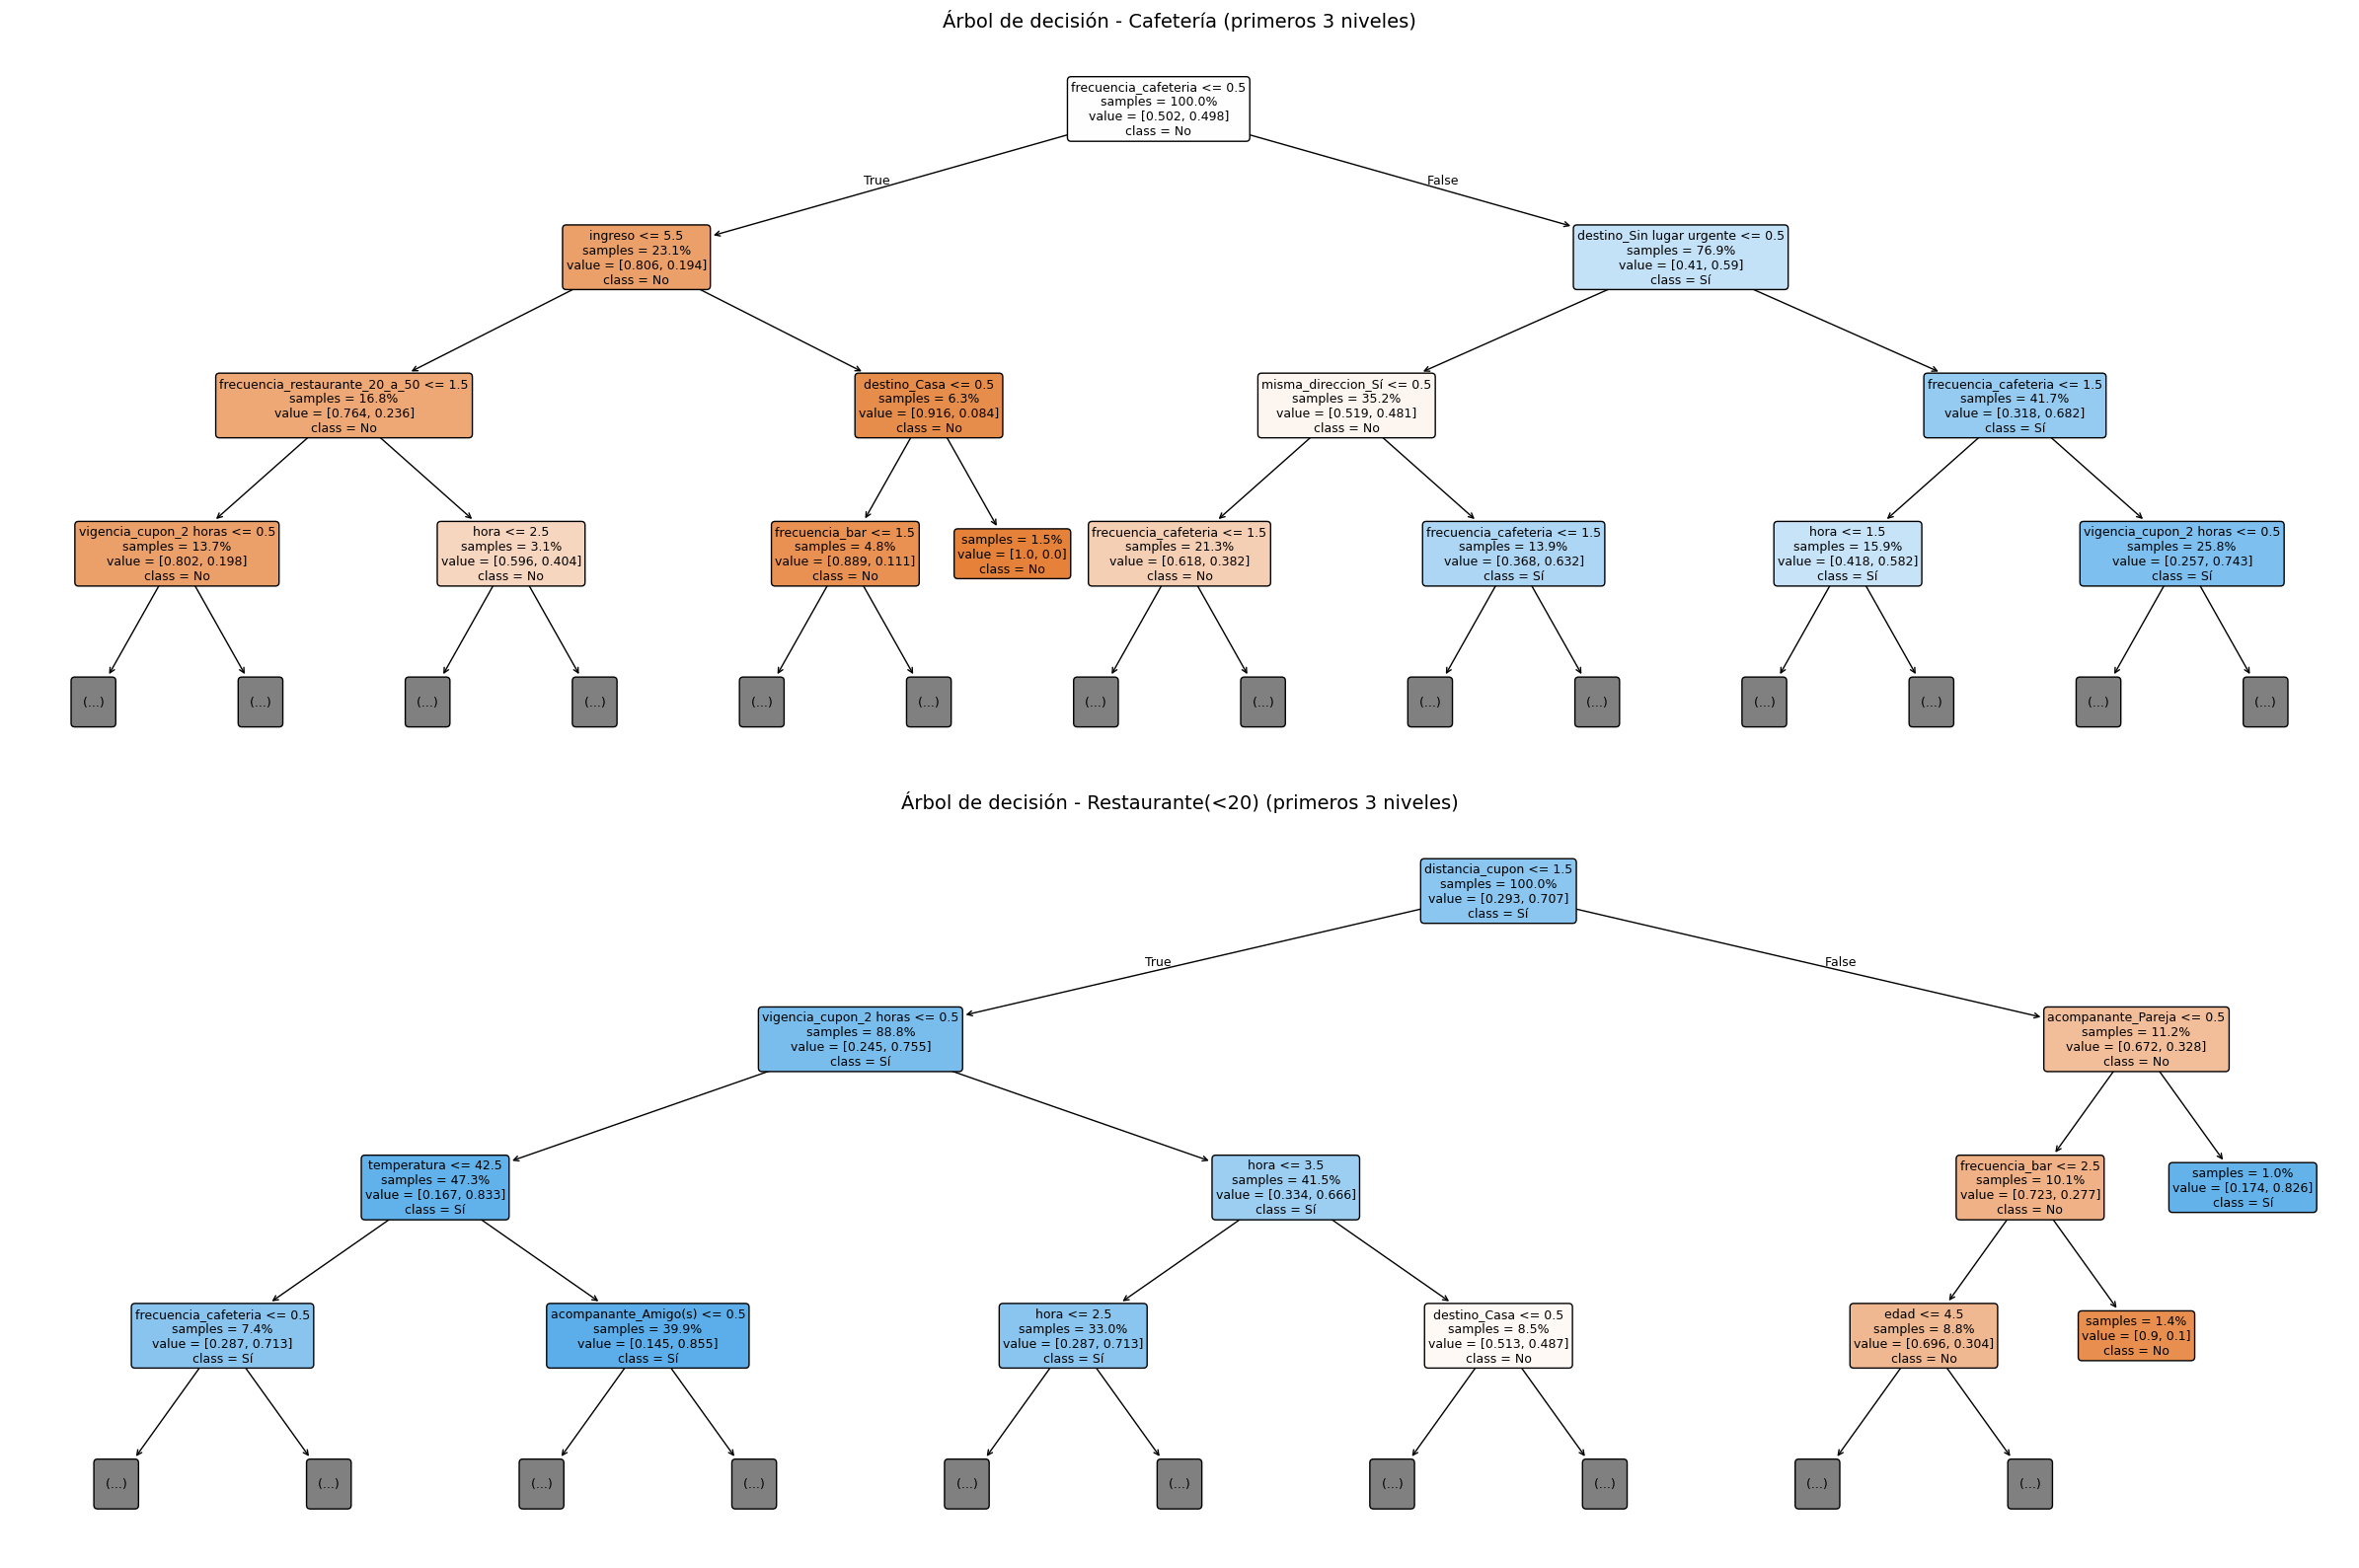

In [43]:
fig, axes = plt.subplots(2, 1, figsize=(24, 16))
for ax, tipo in zip(axes, TIPOS):
    pipe = modelos[tipo]["Árbol de decisión"].best_estimator_
    plot_tree(pipe.named_steps["modelo"], feature_names=list(pipe.named_steps["prep"].get_feature_names_out()),
              class_names=["No", "Sí"], max_depth=3, filled=True, rounded=True, fontsize=9, ax=ax, impurity=False,
              proportion=True)
    ax.set_title(f"Árbol de decisión - {tipo} (primeros 3 niveles)", fontsize=14)
plt.tight_layout()
plt.show()

Para leer las reglas hay que recordar la codificación: frecuencia_cafeteria <= 0.5 quiere decir "nunca", <= 1.5 quiere decir "nunca o menos de 1 vez al mes", hora <= 3.5 quiere decir "antes de las 10 p.m.", edad <= 2.5 quiere decir "26 años o menos", y distancia_cupon > 1.5 quiere decir "a más de 25 minutos". Los `weights` son la cantidad de casos [No, Sí] del entrenamiento que caen en cada hoja.

El árbol de **Cafetería** es bastante fácil de interpretar (profundidad 5). La primera pregunta que hace es si el conductor va alguna vez a cafeterías. Si nunca va, casi todas las hojas terminan en "No" (por ejemplo, si además tiene ingreso de más de \$75.000 y va para la casa: 49 rechazos y 0 aceptaciones). Si sí va, la siguiente pregunta es el destino. Algunas reglas claras:

- Va a cafeterías 1 vez al mes o más + va "Sin lugar urgente" + el cupón dura 1 día + tiene 26 años o menos: **acepta** (166 de 184 casos).
- Va a cafeterías 1 vez al mes o más + va para la casa o el trabajo pero el lugar queda en su misma dirección + no es de noche: **acepta** (186 de 237).
- Nunca va a cafeterías + ingreso de más de \$75.000 + va al bar 1 vez al mes o más: **rechaza** (47 de 49).

El de **Restaurante(<20)** es mucho más grande (14 niveles y 77 hojas), pero sus primeras divisiones también se leen bien: la primera pregunta es si el restaurante queda a más de 25 minutos. Si queda lejos y no va con la pareja, la mayoría termina en rechazo (162 de 224 casos), en cambio si va con la pareja casi todos aceptan (19 de 23). Si queda cerca, lo siguiente es la vigencia, y con vigencia de 1 día y temperatura de 55 o 80 la gran mayoría acepta (por ejemplo, yendo con amigos: 171 de 177 casos).

### Revisión rápida de sesgo por grupo demográfico

Ya que el caso pide evaluar los riesgos de usar datos demográficos, revisamos cómo se comporta el mejor modelo de cada cupón en los distintos grupos de género y edad del test.

In [44]:
# Revision rapida de equidad: recall y tasa de prediccion positiva del mejor modelo por grupo
# demografico en el test (genero y edad)
for tipo in TIPOS:
    nombre, gs = mejor_modelo[tipo]
    c = conjuntos[tipo]
    df = c["X_test"][["genero", "edad"]].copy()
    df["real"] = c["y_test"].values
    df["pred"] = gs.best_estimator_.predict(c["X_test"])
    for col in ["genero", "edad"]:
        tabla = df.groupby(col).apply(lambda g: pd.Series({
            "n": len(g),
            "% real Sí": g["real"].mean() * 100,
            "% predicho Sí": g["pred"].mean() * 100,
            "Recall Sí": recall_score(g["real"], g["pred"], zero_division=0),
            "Recall No": recall_score(g["real"], g["pred"], pos_label=0, zero_division=0),
        }))
        if col == "edad":
            tabla = tabla.reindex(ORDEN["edad"])
        print(f"{tipo} - {col}")
        display(tabla.round(2))

Cafetería - genero


,n,% real Sí,% predicho Sí,Recall Sí,Recall No
genero,,,,,
Femenino,401.0,50.37,50.37,0.77,0.77
Masculino,395.0,49.37,50.38,0.81,0.79


Cafetería - edad


,n,% real Sí,% predicho Sí,Recall Sí,Recall No
edad,,,,,
menor de 21,31.0,67.74,70.97,0.86,0.60
21,168.0,53.57,55.36,0.86,0.79
26,180.0,58.33,57.22,0.81,0.76
31,132.0,43.18,46.21,0.72,0.73
36,65.0,46.15,41.54,0.73,0.86
41,78.0,42.31,46.15,0.67,0.69
46,41.0,58.54,58.54,0.88,0.82
50 o más,101.0,36.63,34.65,0.73,0.88


Restaurante(<20) - genero


,n,% real Sí,% predicho Sí,Recall Sí,Recall No
genero,,,,,
Femenino,300.0,72.00,80.67,0.91,0.46
Masculino,254.0,69.29,81.50,0.91,0.40


Restaurante(<20) - edad

,n,% real Sí,% predicho Sí,Recall Sí,Recall No
edad,,,,,
menor de 21,34.0,67.65,85.29,0.96,0.36
21,95.0,80.00,85.26,0.92,0.42
26,111.0,74.77,81.98,0.90,0.43
31,87.0,77.01,86.21,0.88,0.20
36,65.0,56.92,72.31,0.89,0.50
41,47.0,65.96,82.98,0.97,0.44
46,28.0,85.71,92.86,0.96,0.25
50 o más,87.0,58.62,70.11,0.88,0.56


En **Cafetería** el modelo se comporta parecido entre hombres y mujeres (recall de Sí de 0.77 vs 0.81 y de No de 0.77 vs 0.79), y la tasa de predicción positiva es igual a la real en los dos grupos. Por edad sí hay más diferencias: con los menores de 21 el modelo reconoce muy bien los "Sí" (0.86) pero solo el 60% de sus "No", mientras que con los de 50 o más pasa al revés (0.73 y 0.88). O sea que el modelo aprendió que los jóvenes aceptan más y los mayores menos, y tiende a exagerar ese patrón.

En **Restaurante(<20)** el modelo predice "Sí" más de lo que pasa en la realidad en todos los grupos (por ejemplo 81% predicho vs 72% real en mujeres), y el recall de la clase No varía bastante por edad: 0.56 en los de 50 o más, 0.20 en los de 31 y 0.25 en los de 46 años (aunque estos son solo 28 casos). Hay que tomar estos números con cuidado porque algunos grupos son muy pequeños, pero muestran que el error no se reparte igual entre grupos y que hay que revisarlo antes de usar el modelo en producción.

## Actividad 9 - Video

El video (máximo 3 minutos) se entrega aparte por Bloque Neón.

## Actividad 10 - Predicciones sobre los datos de prueba

Para generar las predicciones finales tomamos la mejor configuración de cada cupón (Random Forest para Cafetería y Random Forest + SMOTE para Restaurante(<20)) y la volvemos a entrenar con **todos** los datos etiquetados de ese cupón (train + test). El test ya cumplió su función de darnos una estimación honesta del desempeño, y reentrenar con más datos debería dar un modelo un poco mejor. Después predecimos cada fila del archivo de prueba con el modelo que corresponde a su tipo de cupón, aplicando exactamente la misma preparación (`preparar` + el preprocesador que está dentro del pipeline).

El resultado se exporta como `Lab3_datos_Prueba.csv`, con las mismas columnas del archivo original más la columna `acepta_cupon` con la predicción ("Sí" / "No"). Lo guardamos con codificación `utf-8-sig` para que las tildes se vean bien si se abre en Excel.

In [45]:
# Reentrenamos la mejor configuracion de cada cupon con TODOS los datos etiquetados de ese cupon
# (train + test) y predecimos sobre el archivo de prueba, usando para cada fila el modelo de su cupon
predicciones = prueba.copy()
predicciones["acepta_cupon"] = None

for tipo in TIPOS:
    nombre, gs = mejor_modelo[tipo]
    modelo_final = clone(gs.best_estimator_).fit(conjuntos[tipo]["X"], conjuntos[tipo]["y"])
    filas = prueba["cupon"] == tipo
    pred = modelo_final.predict(preparar(prueba.loc[filas]))
    predicciones.loc[filas, "acepta_cupon"] = np.where(pred == 1, "Sí", "No")
    print(f"{tipo}: {filas.sum()} filas predichas con {nombre}")

predicciones.to_csv("Lab3_datos_Prueba.csv", index=False, encoding="utf-8-sig")
predicciones[["cupon", "destino", "acompanante", "hora", "vigencia_cupon", "acepta_cupon"]]

Cafetería: 10 filas predichas con Random Forest


Restaurante(<20): 10 filas predichas con Random Forest + SMOTE


,cupon,destino,acompanante,hora,vigencia_cupon,acepta_cupon
0,Cafetería,Trabajo,Solo,7:00 a.m.,2 horas,Sí
1,Cafetería,Sin lugar urgente,Amigo(s),10:00 a.m.,2 horas,Sí
2,Cafetería,Sin lugar urgente,Amigo(s),2:00 p.m.,2 horas,Sí
3,Cafetería,Sin lugar urgente,Pareja,10:00 a.m.,2 horas,Sí
4,Restaurante(<20),Sin lugar urgente,Amigo(s),6:00 p.m.,2 horas,Sí
5,Restaurante(<20),Sin lugar urgente,Hijo(s),2:00 p.m.,1 día,Sí
6,Restaurante(<20),Sin lugar urgente,Solo,2:00 p.m.,2 horas,No
7,Restaurante(<20),Sin lugar urgente,Amigo(s),6:00 p.m.,1 día,Sí
8,Restaurante(<20),Sin lugar urgente,Amigo(s),2:00 p.m.,2 horas,Sí
9,Cafetería,Casa,Solo,6:00 p.m.,1 día,No


In [46]:
predicciones.groupby("cupon")["acepta_cupon"].value_counts()

cupon             acepta_cupon
Cafetería         Sí              7
                  No              3
Restaurante(<20)  Sí              9
                  No              1
Name: count, dtype: int64

De los 10 escenarios de Cafetería el modelo predice que 7 aceptan y 3 no, y de los 10 de Restaurante(<20) predice 9 aceptaciones y 1 rechazo, lo cual es coherente con las proporciones de cada cupón en los datos de entrenamiento. Por ejemplo, los rechazos de Cafetería corresponden a viajes hacia la casa en la tarde o al trabajo con cupón de 1 día, que son contextos donde la exploración ya mostraba tasas bajas de aceptación.

# Análisis de resultados

### ¿Qué características del contexto de conducción o del perfil del conductor parecen estar más relacionadas con la aceptación de cada tipo de cupón?

En **Cafetería** lo que más pesa, de lejos, es el hábito: la frecuencia con la que el conductor va a cafeterías. Los que nunca van casi no aceptan (18.8%) y los que van 1 a 3 veces al mes o más aceptan entre 65% y 69%. Es la primera división del árbol, el coeficiente más grande de la logística y la variable con más importancia por permutación. Después vienen variables de contexto: el destino (sin lugar urgente se acepta más, hacia la casa mucho menos), la hora (el mejor momento es a las 10 a.m.), la vigencia (1 día mejor que 2 horas), si va con amigos y si el lugar queda en la misma dirección. Del perfil aparecen la ocupación, el ingreso, el estado civil y la edad (los menores de 21 aceptan más), pero con mucho menos peso (en la permutación bajan el AUC entre 0.016 y 0.046, contra 0.17 de frecuencia_cafeteria).

En **Restaurante(<20)** el hábito pesa mucho menos y lo que más importa es el contexto: la vigencia del cupón (83% de aceptación con 1 día vs 59% con 2 horas), el destino, la hora (2 p.m. y 6 p.m., horas de comer), la distancia (a más de 25 minutos la aceptación se cae a 33%) y el clima (con lluvia o nieve se acepta mucho menos). Del perfil, ocupación, edad y educación aparecen en la importancia por permutación, pero con efectos más pequeños.

### ¿Existen variables que podrían ser redundantes o poco informativas?

Sí, varias. Algunas las quitamos desde la preparación: `direccion_opuesta` es exactamente lo contrario de `misma_direccion`, `tiempo_cupon_mayor_5min` es constante, `vehiculo` está vacía en el 99% de los casos y las dos variables de tiempo (15 y 25 min) eran en realidad una sola variable de distancia.

Otras son parcialmente redundantes: el clima y la temperatura (nieve siempre es 30 °F y lluvia siempre 55 °F), y el destino con la hora (al trabajo siempre se va a las 7 a.m.). Esto hace que sea difícil separar el efecto de una y otra.

Y hay variables poco informativas según los modelos: el género (las tasas de aceptación casi no cambian, 49% vs 51% en Cafetería), `tiene_hijos`, `misma_direccion` y el clima en Cafetería, y temperatura y frecuencia_cafeteria en Restaurante (importancias por permutación cercanas a cero o negativas). La regresión logística con L1 de Cafetería llevó 12 de las 55 columnas a cero, la mayoría categorías de ocupación con muy pocos casos. También vale la pena mencionar las frecuencias de los otros tipos de lugar (por ejemplo frecuencia_comida_para_llevar en el modelo de Cafetería), que aportan poco y podrían quitarse para simplificar.

### ¿El desempeño y el comportamiento de los modelos difieren entre Cafetería y Restaurante(<20)? Si es así, ¿a qué atribuye esa diferencia?

Sí, bastante. Mirando el F1 de la clase Sí parecería que Restaurante es más fácil (0.85 vs 0.78), pero eso es engañoso porque en Restaurante el 70% acepta y solo decir "Sí" a todo ya da 0.83. Con el F1 macro, que tiene en cuenta las dos clases, se ve que en realidad es al revés: Cafetería llega a 0.78 y Restaurante a 0.69. En Cafetería el modelo se equivoca parecido hacia los dos lados (recall de 0.79 en Sí y 0.78 en No), mientras que en Restaurante reconoce casi todos los Sí pero se le escapan más de la mitad de los No.

Creemos que la diferencia se debe a tres cosas:

1. **El desbalance**: en Restaurante hay menos ejemplos de rechazo para aprender y el modelo tiende a irse hacia la clase mayoritaria.
2. **Una señal dominante en Cafetería**: la frecuencia de visita a cafeterías separa muy bien a la gente que acepta de la que no. En Restaurante no hay una variable así, casi todo el mundo va a restaurantes baratos y el rechazo depende de combinaciones de contexto (lejos, lluvia, cupón corto, de noche), que son más difíciles de capturar.
3. **El tamaño de los datos**: Restaurante tiene unos 1200 escenarios menos, y su clase minoritaria tiene solo unos 810 casos.

También cambia qué tanto ayuda la complejidad: en Cafetería el Random Forest le saca 5 puntos de F1 macro al árbol, en Restaurante solo 1, y en Restaurante la logística necesitó una regularización muy fuerte para no quedarse en "Sí" para todos.

### ¿Aplicar balanceo de clases en Restaurante(<20) mejoró el modelo? Justifique considerando tanto el F1-score general, así como el recall de la clase minoritaria.

Mejoró en una cosa y casi no cambió la otra. El **recall de la clase minoritaria (No) subió en los tres algoritmos** en test: de 0.43 a 0.60 en la logística, de 0.39 a 0.72 en el árbol y de 0.40 a 0.43 en Random Forest. En cambio el **F1 general (macro) se quedó prácticamente igual** en la logística y en Random Forest: con Random Forest pasó de 0.698 a 0.710 en validación cruzada (el mejor de todos) y de 0.685 a 0.687 en test, y en la logística cambió menos de 0.01, que está dentro de la variabilidad entre folds. La excepción es el árbol, donde el F1 macro sí empeoró (de 0.663 a 0.604 en test), porque con SMOTE la búsqueda terminó escogiendo un árbol de profundidad 2 que se va mucho hacia la clase No. Lo que sí bajó siempre fue el F1 de la clase Sí, porque el modelo empieza a decir "No" en algunos casos que en realidad aceptaban.

Entonces SMOTE no hace al modelo más inteligente, más bien cambia el equilibrio entre los dos tipos de error: se equivoca menos dejando pasar rechazos y un poco más dejando de ofrecer cupones que sí se habrían aceptado. Por eso nuestra conclusión es que sí conviene usarlo, pero con Random Forest, porque para Ruta Alpes detectar los rechazos es justamente lo que permite no molestar a los conductores con ofertas irrelevantes, y eso se logra sin perder desempeño general. Con el árbol no lo recomendaríamos. Si el objetivo fuera solo maximizar cupones aceptados, el modelo sin balancear sería igual de bueno.

### A partir de alguno de los modelos de árbol o Random Forest describa, en términos de reglas o de importancia de variables, las características que llevan a aceptar o rechazar un cupón. Incluya la utilidad y la limitación de este tipo de interpretación.

Usando el árbol de decisión de Cafetería (profundidad 5), las reglas principales son:

- **Rechaza** casi siempre si nunca va a cafeterías, y todavía más si además tiene ingreso alto y va para la casa (49 de 49 casos) o tiene ingreso alto y va a bares (47 de 49).
- **Acepta** si va a cafeterías al menos 1 vez al mes, va sin lugar urgente, el cupón dura 1 día y tiene 26 años o menos (166 de 184), o si va a cafeterías seguido, el lugar le queda en la misma dirección y no es de noche (186 de 237).
- Con vigencia de 2 horas y hora tarde la probabilidad baja aunque la persona sí vaya a cafeterías.

Con el Random Forest (importancia por permutación) se ve lo mismo pero resumido: en Cafetería frecuencia_cafeteria es por mucho la variable más importante, y en Restaurante las que más pesan son la vigencia, el destino, la ocupación, la educación y la hora.

**Utilidad**: este tipo de reglas se le pueden explicar a alguien de negocio sin hablar de matemáticas ("si la persona nunca va a cafeterías, no le mandes el cupón"), sirven para diseñar estrategias concretas (preferir cupones de 1 día, no ofrecer lugares lejanos) y permiten revisar si el modelo está usando cosas que no debería, como el género (que aparece en una rama del árbol de Cafetería).

**Limitaciones**: el árbol interpretable no es el mejor modelo (F1 de 0.70 vs 0.78 del bosque), entonces las reglas sencillas no cuentan toda la historia. El árbol de Restaurante ya tiene 77 hojas y deja de ser fácil de leer. Las importancias del bosque no dicen la dirección del efecto, la importancia por impureza está sesgada hacia variables con muchos valores (por eso ingreso y edad salen tan arriba), y la importancia por permutación se reparte entre variables correlacionadas (por ejemplo destino y hora). Además los distintos métodos no siempre coinciden: la distancia es la primera división del árbol de Restaurante, pero en la permutación del bosque sale con importancia casi nula. Y lo más importante, todo esto son asociaciones, no causas: que los jóvenes acepten más no quiere decir que la edad sea la razón.

### ¿Cómo podría integrarse este tipo de modelo en una aplicación de conducción para decidir en tiempo real qué cupón mostrar?

Una forma sería así: el modelo se entrena fuera de línea (por ejemplo cada semana o cada mes con los datos nuevos) y se guarda el pipeline completo, que ya incluye la limpieza y la codificación. Cuando el conductor va manejando, la app arma el escenario con lo que ya sabe: destino, acompañantes (si los registró), clima y temperatura (de un servicio de clima), hora, y para cada establecimiento cercano la distancia y si queda en su misma dirección. Con eso le pide al modelo de cada tipo de cupón la probabilidad de aceptación, y solo muestra el cupón con la probabilidad más alta y únicamente si supera un umbral. Ese umbral es una decisión de negocio: subirlo significa mandar menos cupones pero más acertados (menos molestia), bajarlo significa llegar a más gente.

Algunas cosas prácticas: un Random Forest predice en milisegundos, entonces no hay problema de tiempo real. Habría que limitar cuántas notificaciones se mandan por viaje y mostrarlas cuando sea seguro (por ejemplo en un semáforo o antes de arrancar, no en plena autopista). Y es importante registrar si el conductor aceptó o no cada cupón que se mostró, para monitorear el desempeño del modelo, detectar si los patrones cambian con el tiempo y reentrenar. También se podría hacer pruebas A/B comparando el modelo contra mandar cupones al azar para medir si de verdad sube la aceptación.

### ¿Qué limitaciones tendría un sistema automático que decide qué ofertas mostrar a cada conductor según su perfil demográfico?

- **Los datos no son de comportamiento real**: vienen de una encuesta con escenarios hipotéticos (por eso destino y hora están tan amarrados). Lo que la gente dice que haría no siempre es lo que hace.
- **El desempeño es limitado**: incluso el mejor modelo de Cafetería se equivoca en más o menos 1 de cada 5 casos, y el de Restaurante no detecta más de la mitad de los rechazos. El sistema va a mandar cupones que molestan y va a dejar de mandar otros que sí servían.
- **Generaliza estereotipos**: el modelo aprende promedios de grupo y se los aplica a cada persona. Si los mayores de 50 aceptan menos en promedio, el sistema les va a ofrecer menos cupones a todos, aunque a muchos de ellos sí les interesen. Vimos que el error no es igual entre grupos de edad.
- **Se retroalimenta**: si a un grupo casi no se le muestran cupones, nunca se van a recolectar datos de si los aceptan, y el modelo va a seguir pensando que no les interesan.
- **Los perfiles cambian y a veces faltan**: la edad, el ingreso o el estado civil cambian con el tiempo o el usuario no los quiere dar, y el modelo depende de que estén.
- **Privacidad y regulación**: usar datos demográficos para decidir qué se le muestra a alguien necesita consentimiento y transparencia, y puede chocar con normas de protección de datos (en Colombia la Ley 1581 de 2012).
- **Solo cubre dos tipos de cupón** y escenarios específicos, no se puede asumir que funcione para otras ciudades u otros tipos de negocio sin volver a entrenarlo.

### ¿Qué fuentes de sesgo podrían estar presentes en los datos o en el proceso de modelado, en particular al usar variables como edad, género, estado civil o nivel de ingreso para personalizar ofertas? ¿Qué implicaciones tendría este tipo de personalización si se usara para fines distintos a cupones (por ejemplo, precios dinámicos)?

**Fuentes de sesgo en los datos**: hay sesgo de muestreo, porque los datos vienen de una encuesta y no representan necesariamente a todos los conductores (por ejemplo los viudos son solo 130 casos y los menores de 21 son pocos, entonces el modelo aprende con muy poca información sobre ellos). Hay sesgo de respuesta, porque son respuestas a escenarios hipotéticos. Y hay variables que pueden funcionar como "proxy" de otras: la ocupación y el ingreso están relacionados con la edad, el género o el nivel socioeconómico, entonces aunque se quitara el género del modelo, parte de esa información seguiría entrando por otras variables. Las categorías también son simplificaciones, por ejemplo el género solo tiene dos opciones y el ingreso viene en rangos.

**Fuentes de sesgo en el modelado**: las decisiones que tomamos también pueden meter sesgo. Imputar con la moda asigna a la gente sin dato el hábito más común. SMOTE genera conductores sintéticos interpolando, que pueden no parecerse a nadie real. Y escoger el modelo por una métrica global (F1 macro) no garantiza que funcione igual de bien para todos los grupos, como vimos en la revisión por edad, donde el recall de la clase No va de 0.20 a 0.56 según el grupo en Restaurante.

**Implicaciones en otros usos**: con cupones el daño es relativamente pequeño (a alguien le llega o no le llega un descuento de un café). Pero si la misma lógica se usara para **precios dinámicos**, el problema es mucho más serio. El modelo aprende quién es más propenso a aceptar una oferta, y eso se puede usar para cobrarle más a quien "aguanta" pagar más o tiene menos alternativas. Por ejemplo, si se infiere que alguien con cierto ingreso, edad o estado civil va a pagar igual, se le subiría el precio, lo cual sería discriminación de precios basada en características personales que la persona no puede cambiar. Además sería muy poco transparente, porque el cliente no sabe por qué le cobran distinto. Lo mismo aplica para otros usos como créditos o seguros, donde estas decisiones pueden afectar el acceso a servicios. Por eso recomendaríamos priorizar las variables de contexto (que fueron las más importantes de todos modos), auditar el modelo por grupos demográficos de forma periódica, y no usar este tipo de perfilamiento para fijar precios.

# Uso de herramientas de IA generativa

**Herramienta y tipo de uso.** Se utilizó Claude como herramienta de apoyo general durante el desarrollo del laboratorio. Se usó principalmente para depurar problemas que aparecieron en los resultados, para revisar que los textos coincidieran con los outputs y como apoyo en la redacción de algunas respuestas del análisis de resultados. Todo el código fue ejecutado y revisado por nosotros.

**Prompts principales utilizados.**
- ""
- "Mejora la redacción de las conclusiones."

**Análisis crítico del resultado.**
- La primera versión escogía los hiperparámetros con el F1 de la clase "Sí". Al revisar los resultados se vio que en Restaurante(<20) la búsqueda de regresión logística con SMOTE terminaba escogiendo un modelo que predecía "Sí" para todos (recall de la clase No igual a 0), y que un modelo trivial ya tenía F1 de 0.83. Por eso se cambió el criterio de selección a F1 macro y se agregó una línea base para comparar. Esto lo pudimos detectar gracias a lo visto en el curso sobre métricas en problemas desbalanceados.
- La importancia por permutación calculada con F1 daba valores casi todos cercanos a cero o negativos en Restaurante, por lo que se cambió a ROC AUC, que no depende del umbral.
- Se verificó que SMOTE quedara dentro del pipeline para que solo se aplique a los folds de entrenamiento y no haya fuga de información, y se dejó explícita la limitación de aplicar SMOTE sobre variables one-hot.
- Al interpretar la regresión logística de Restaurante se revisó por qué ganaba un C tan pequeño, y la explicación (liblinear penaliza también el intercepto) se contrastó con la documentación de scikit-learn.
- En la revisión final encontramos que, después de volver a ejecutar el notebook, varios textos ya no coincidían con los outputs (por ejemplo el árbol con SMOTE cambió de hiperparámetros y de resultados), entonces corregimos todos los números con los de la ejecución final. También quitamos una nota que decía que el parámetro `penalty` de la regresión logística estaba deprecado, porque eso no aplica para la versión de scikit-learn que usamos (1.6.1).

**Decisiones tomadas por nosotros.** Decidimos trabajar con un modelo separado para cada cupón, las variables que se eliminaban o se combinaban en la preparación, usar el F1 macro como criterio de selección por el desbalance de Restaurante(<20), los rangos de hiperparámetros de cada búsqueda y la recomendación final sobre SMOTE pensando en el costo de molestar a los conductores. También decidimos agregar la revisión del desempeño por grupos de género y edad para respaldar la discusión de sesgo con datos y no solo con argumentos. Las respuestas del análisis de resultados las revisamos y ajustamos con los valores obtenidos en la ejecución del notebook. Lo que más aprendimos fue que en un problema desbalanceado una métrica que parece buena (el F1 de la clase mayoritaria) puede esconder un modelo que no sirve, y que técnicas como SMOTE no hacen al modelo más preciso sino que cambian el balance entre los dos tipos de error.